# Hafta 11 – GPT-2'yi Hızlı Eğitilebilir Hâle Getirmek

Geçen hafta GPT-2 mimarisini kendimiz yazdık ve OpenAI ağırlıklarıyla Hugging Face ile aynı logits'i aldık. Bu hafta modeli **sıfırdan eğitmeye** hazırlıyoruz. Üç soru var:
1. **Doğru eğitim:** Veriyi nasıl besleriz, parametreleri nasıl paylaşırız, ağırlıkları nasıl başlatırız?
2. **Hızlı eğitim:** GPU'yu nasıl daha verimli kullanırız?
3. **Kararlı eğitim:** GPT-3'ün optimizer ayarlarını ve büyük batch'i küçük GPU'da nasıl kurarız?


> **Not:** Hafta 10 notebook'unu değiştirmedim. Oradaki model, HF ağırlıklarıyla eşdeğerlik testi için yazılmıştı. Bu haftaki değişiklikler (flash attention, weight tying, yeni init, vocab 50.304) o testi bozardı. Bu yüzden model sınıfı burada geliştirilmiş haliyle yeniden yazıldı.


## 0. Kurulum ve Donanım Kontrolü

### Neyi Yapıyoruz?
Kütüphaneleri yüklüyor, cihazı (CUDA / MPS / CPU) buluyor ve GPU'nun hangi hızlandırmaları desteklediğini kontrol ediyoruz.

### Neden Yapıyoruz?
2. görevde bazı adımlar donanıma bağlı:
* **TF32 ve bfloat16** için Ampere (compute capability ≥ 8.0) veya daha yeni bir GPU gerekir. RTX 30xx/40xx ve A100 destekler. Colab T4 (7.5) desteklemez.
* **torch.compile** CUDA'da Triton kullanır. Triton Windows'ta varsayılan olarak gelmez (`pip install triton-windows` gerekir).

Notebook bu bayrakları başta belirler ve desteklenmeyen adımları **otomatik atlayıp nedenini yazar.**

In [1]:
%pip install -q tiktoken

In [2]:
# %pip install tiktoken matplotlib pandas
import math, time, inspect, os, dataclasses, contextlib, urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
import tiktoken

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
device_type = "cuda" if device.startswith("cuda") else device
print("PyTorch:", torch.__version__, "| cihaz:", device)

SUPPORTS_TF32 = SUPPORTS_BF16 = False
VRAM_GB = 0
if device == "cuda":
    props = torch.cuda.get_device_properties(0)
    cap = torch.cuda.get_device_capability(0)
    VRAM_GB = props.total_memory / 1e9
    SUPPORTS_TF32 = cap[0] >= 8
    SUPPORTS_BF16 = cap[0] >= 8 and torch.cuda.is_bf16_supported()
    print(f"GPU: {props.name} | VRAM: {VRAM_GB:.1f} GB | compute capability: {cap}")

def compile_available():
    if device != "cuda":
        return False, "torch.compile bu notebookta yalnızca CUDA'da deneniyor"
    try:
        import triton
        return True, f"triton {triton.__version__} bulundu"
    except ImportError:
        return False, "triton yok (Windows'ta: pip install triton-windows)"

COMPILE_OK, COMPILE_MSG = compile_available()
print("TF32 destekli mi:", SUPPORTS_TF32)
print("bfloat16 destekli mi:", SUPPORTS_BF16)
print("torch.compile:", COMPILE_OK, "-", COMPILE_MSG)

PyTorch: 2.14.1+cu130 | cihaz: cuda
GPU: Tesla T4 | VRAM: 15.6 GB | compute capability: (7, 5)
TF32 destekli mi: False
bfloat16 destekli mi: False
torch.compile: True - triton 3.8.0 bulundu


In [3]:
# Veri: Tiny Shakespeare (geçen haftaki input.txt). Dosya yoksa indirir.
if not os.path.exists("input.txt"):
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    urllib.request.urlretrieve(url, "input.txt")

text = open("input.txt", encoding="utf-8").read()
enc = tiktoken.get_encoding("gpt2")
all_tokens = torch.tensor(enc.encode(text), dtype=torch.long)
print(f"{len(text):,} karakter -> {len(all_tokens):,} token (karakter/token = {len(text)/len(all_tokens):.2f})")

# Micro-batch boyutunu VRAM'e göre seç. Karpathy A100 (80 GB) üzerinde B=16, T=1024 ile başlıyor.
# 1. ve 2. görevde attention matrisi (B, n_head, T, T) belleğe yazılıyor, bu yüzden küçük GPU'da T'yi küçük tutuyoruz.
if device == "cuda":
    B, T = (16, 1024) if VRAM_GB > 30 else (4, 1024) if VRAM_GB > 14 else (4, 512)
else:
    B, T = 2, 256
print(f"Micro-batch: B={B}, T={T} -> adım başına {B*T:,} token")

1,115,394 karakter -> 338,025 token (karakter/token = 3.30)
Micro-batch: B=4, T=1024 -> adım başına 4,096 token


## Model: Geçen Haftanın GPT-2'si + Bu Haftanın Değişiklikleri

### Neyi Yapıyoruz?
Hafta 10'daki `GPT` sınıfını aldık ve deneylerde açıp kapatabileceğimiz üç bayrak ekledik:

| Bayrak | Ne yapar | Görev |
|---|---|---|
| `weight_tying` | `wte` ile `lm_head` aynı matrisi paylaşır | 1 |
| `residual_scale` | Residual'a yazan katmanların std'sini $1/\sqrt{2 \cdot n_{layer}}$ ile küçültür | 1 |
| `use_flash` | Attention'ı `F.scaled_dot_product_attention` ile hesaplar | 2 |

Ayrıca `vocab_size` artık parametre (50.257 veya 50.304). Optimizer kurulumu (`configure_optimizers`) da modelin içinde, 3. görevde kullanacağız.

### Hafta 10'dan farkları
1. `__init__` sonunda `self.apply(self._init_weights)` var. PyTorch'un varsayılan başlatması yerine GPT-2'ninkini kullanıyoruz.
2. `c_proj` katmanlarına `NANOGPT_SCALE_INIT` işareti koyduk. Residual stream'e **doğrudan yazan** katmanlar bunlar (attention çıkışı ve MLP çıkışı).
3. `forward` her zaman tüm konumların logits'ini döndürüyor. Eğitimde zaten hepsine ihtiyaç var.

In [4]:
@dataclasses.dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12
    n_head: int = 12
    n_embd: int = 768
    use_flash: bool = False       # Görev 2: flash attention
    weight_tying: bool = True     # Görev 1: wte <-> lm_head paylaşımı
    residual_scale: bool = True   # Görev 1: 1/sqrt(2*n_layer) ölçekleme


class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1      # residual stream'e yazan katman
        self.n_head, self.n_embd = config.n_head, config.n_embd
        self.use_flash = config.use_flash
        if not self.use_flash:
            self.register_buffer("bias", torch.tril(torch.ones(config.block_size, config.block_size))
                                 .view(1, 1, config.block_size, config.block_size), persistent=False)

    def forward(self, x):
        B, T, C = x.size()
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        if self.use_flash:
            # T x T attention matrisini belleğe hiç yazmadan hesaplar
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        else:
            att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))
            att = att.masked_fill(self.bias[:, :, :T, :T] == 0, float("-inf"))
            att = F.softmax(att, dim=-1)
            y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.c_proj(y)


class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate="tanh")
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1      # residual stream'e yazan katman

    def forward(self, x):
        return self.c_proj(self.gelu(self.c_fc(x)))


class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))   # 1. ekleme
        x = x + self.mlp(self.ln_2(x))    # 2. ekleme  -> blok başına 2 ekleme
        return x


class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte=nn.Embedding(config.vocab_size, config.n_embd),
            wpe=nn.Embedding(config.block_size, config.n_embd),
            h=nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f=nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        if config.weight_tying:
            self.transformer.wte.weight = self.lm_head.weight   # aynı tensör, iki yerde
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, "NANOGPT_SCALE_INIT") and self.config.residual_scale:
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.size()
        assert T <= self.config.block_size
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        x = self.transformer.wte(idx) + self.transformer.wpe(pos)
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    def configure_optimizers(self, weight_decay, learning_rate, device_type, verbose=True):
        params = {pn: p for pn, p in self.named_parameters() if p.requires_grad}
        decay = {pn: p for pn, p in params.items() if p.dim() >= 2}    # matmul ağırlıkları + embedding'ler
        nodecay = {pn: p for pn, p in params.items() if p.dim() < 2}   # bias'lar + LayerNorm parametreleri
        groups = [
            {"params": list(decay.values()), "weight_decay": weight_decay},
            {"params": list(nodecay.values()), "weight_decay": 0.0},
        ]
        stats = dict(
            n_decay_tensors=len(decay), n_decay_params=sum(p.numel() for p in decay.values()),
            n_nodecay_tensors=len(nodecay), n_nodecay_params=sum(p.numel() for p in nodecay.values()),
            nodecay_names=list(nodecay.keys()),
        )
        fused_available = "fused" in inspect.signature(torch.optim.AdamW).parameters
        use_fused = fused_available and device_type == "cuda"
        if verbose:
            print(f"weight decay UYGULANAN : {stats['n_decay_tensors']} tensör, {stats['n_decay_params']:,} parametre")
            print(f"weight decay UYGULANMAYAN: {stats['n_nodecay_tensors']} tensör, {stats['n_nodecay_params']:,} parametre")
            print(f"fused AdamW: {use_fused}")
        opt = torch.optim.AdamW(groups, lr=learning_rate, betas=(0.9, 0.95), eps=1e-8, fused=use_fused)
        return opt, stats


def count_params(model):
    # named_parameters paylaşılan tensörü bir kez sayar, weight tying'de doğru sonucu verir
    return sum(p.numel() for p in model.parameters())


# Hızlı sağlık kontrolü: rastgele başlatılmış modelin ilk loss'u ~ ln(vocab) olmalı
torch.manual_seed(1337)
_m = GPT(GPTConfig()).to(device)
_x = all_tokens[: B * T + 1].to(device)
with torch.no_grad():
    _, _loss = _m(_x[:-1].view(B, T), _x[1:].view(B, T))
print(f"Parametre sayısı: {count_params(_m):,}")
print(f"İlk loss: {_loss.item():.4f} | ln(50257) = {math.log(50257):.4f}")
del _m, _x, _loss
if device == "cuda": torch.cuda.empty_cache()

Parametre sayısı: 124,439,808
İlk loss: 10.9286 | ln(50257) = 10.8249


> **Geçen haftaya not:** İlk loss 10,93 çıktı, hafta 10'daki 10,87'den bile biraz yüksek. Yani std=0,02 başlatması ilk loss'u değiştirmedi. Sebep: PyTorch'un varsayılan Linear başlatmasının std'si $1/\sqrt{3 \cdot 768} \approx 0{,}0208$, yani 0,02 ile neredeyse aynı. Weight tying ile logit std'si $\approx 0{,}02 \cdot \sqrt{768} \approx 0{,}55$ oluyor. Bu da beklenen loss'u $\ln(50257) + \sigma^2/2 \approx 10{,}97$'ye çıkarıyor. Ölçtüğümüz 10,93 bununla tutarlı. Hafta 10'la aradaki farkın bir kısmı da batch boyutundan geliyor (128 token yerine 4.096 token).

---
# GÖREV 1 — Data Loader, Weight Tying ve Başlangıç Değerleri (1:02:00 – 1:22:18)

## 1.1 Data Loader

### Teori
Geçen hafta tek bir batch'i 200 kez gösterip ezberlettik. Gerçek eğitimde model her adımda **yeni** bir parça görmeli. Dil modelinde girdi ve hedef aynı metindir, hedef sadece **1 token kaydırılmıştır**:

```
token dizisi:  [t0 t1 t2 t3 t4 t5 t6 t7 t8]
x (girdi)   :  [t0 t1 t2 t3 t4 t5 t6 t7]
y (hedef)   :     [t1 t2 t3 t4 t5 t6 t7 t8]
```

### Mantık
* Her adımda metinden `B*T + 1` token kesiyoruz. `+1`, son konumun hedefi için.
* `x = buf[:-1]`, `y = buf[1:]`, ikisini `(B, T)` şekline getiriyoruz.
* İmleci `B*T` kadar ilerletiyoruz. Bir sonraki parça sığmıyorsa başa dönüyoruz. Bu bir **epoch**.

### Kod

In [5]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# class DataLoaderLite:
#     def __init__(self, tokens, B, T, verbose=True):
#         self.tokens, self.B, self.T = tokens, B, T
#         self.current_position = 0
#         if verbose:
#             print(f"{len(tokens):,} token | 1 epoch = {len(tokens) // (B * T)} batch")
#
#     def next_batch(self):
#         B, T = self.B, self.T
#         buf = self.tokens[self.current_position: self.current_position + B * T + 1]
#         x = buf[:-1].view(B, T)
#         y = buf[1:].view(B, T)
#         self.current_position += B * T
#         if self.current_position + B * T + 1 > len(self.tokens):   # sonraki batch sığmıyorsa başa dön
#             self.current_position = 0
#         return x, y
#
#
# loader = DataLoaderLite(all_tokens, B, T)
# x, y = loader.next_batch()
# print("x şekli:", tuple(x.shape), "| y şekli:", tuple(y.shape))
#
# # Kaydırmayı gözle görelim: ilk satırın ilk 10 konumu
# print(f"\n{'konum':>5} | {'x (girdi)':<16} | {'y (hedef)':<16}")
# for i in range(10):
#     print(f"{i:>5} | {repr(enc.decode([x[0, i].item()])):<16} | {repr(enc.decode([y[0, i].item()])):<16}")

In [6]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# # Görsel: loader metin üzerinde nasıl ilerliyor? Testere dişi = epoch'lar.
# viz_loader = DataLoaderLite(all_tokens, B, T, verbose=False)
# n_batches = len(all_tokens) // (B * T)
# positions = []
# for _ in range(int(n_batches * 2.5)):
#     positions.append(viz_loader.current_position)
#     viz_loader.next_batch()
#
# plt.figure(figsize=(10, 3.5))
# plt.plot(positions, drawstyle="steps-post", color="#2980b9")
# plt.axhline(len(all_tokens), color="gray", ls="--", label="metnin sonu")
# plt.title("DataLoaderLite: batch başlangıç konumu (her düşüş = yeni epoch)")
# plt.xlabel("Adım"); plt.ylabel("Token konumu"); plt.legend(); plt.grid(alpha=0.3)
# plt.tight_layout(); plt.show()

## 1.2 Weight Tying (Ağırlık Paylaşımı)

### Teori
GPT-2'de iki büyük matris aynı boyutta:
* `wte`: **(vocab, C)**, token id'sini vektöre çevirir (girdi tarafı).
* `lm_head`: **(vocab, C)**, vektörü her token için bir skora çevirir (çıktı tarafı).

GPT-2 (ve "Attention is All You Need") bu iki matrisi **aynı tensör** yapar (Press & Wolf, 2017).

### Mantık
* Anlamca benzer iki token girişte yakın embedding'lere sahip olmalı. Çıkışta da benzer bağlamlarda benzer skor almalı. İki matris aynı benzerlik yapısını öğreniyor, bu yüzden paylaşmak mantıklı bir varsayım (inductive bias).
* Paylaşılan matris **iki yerden gradyan alır**. Nadir token'ların embedding'i de çıkış katmanından sinyal alarak daha iyi öğrenilir.
* Parametre tasarrufu: $50.257 \times 768 = 38.597.376$. Bu, paylaşımlı 124M modelin **%31'i**, paylaşımsız 163M modelin **%23,7'si**. Karpathy'nin videoda söylediği "~%30" birinci oran.

### Kod
Aynı modeli paylaşımlı ve paylaşımsız kurup parametreleri sayıyoruz. Ardından OpenAI'ın GPT-2'sinde bu iki matrisin gerçekten aynı bellek adresinde olduğunu kontrol ediyoruz.

In [7]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# m_tied = GPT(GPTConfig(weight_tying=True))
# m_untied = GPT(GPTConfig(weight_tying=False))
# n_tied, n_untied = count_params(m_tied), count_params(m_untied)
#
# print(f"Paylaşımlı    : {n_tied:,}")
# print(f"Paylaşımsız   : {n_untied:,}")
# print(f"Kazanç        : {n_untied - n_tied:,}  (= 50257 x 768 = {50257*768:,})")
# print(f"Toplama oranı : %{100 * (n_untied - n_tied) / n_untied:.1f}")
# print("Aynı tensör mü (data_ptr):", m_tied.transformer.wte.weight.data_ptr() == m_tied.lm_head.weight.data_ptr())
#
# # OpenAI GPT-2'de de paylaşımlı mı? (transformers kuruluysa)
# try:
#     from transformers import GPT2LMHeadModel
#     hf = GPT2LMHeadModel.from_pretrained("gpt2")
#     sd = hf.state_dict()
#     print("HF GPT-2 wte == lm_head (değer):", torch.equal(sd["transformer.wte.weight"], sd["lm_head.weight"]))
#     print("HF GPT-2 aynı bellek adresi    :", sd["transformer.wte.weight"].data_ptr() == sd["lm_head.weight"].data_ptr())
#     del hf, sd
# except Exception as e:
#     print("HF kontrolü atlandı:", e)

In [8]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# # Görsel: parametreler nereye gidiyor?
# def param_breakdown(m):
#     C, V = m.config.n_embd, m.config.vocab_size
#     wte = V * C
#     wpe = m.config.block_size * C
#     blocks = sum(p.numel() for p in m.transformer.h.parameters())
#     ln_f = sum(p.numel() for p in m.transformer.ln_f.parameters())
#     lm_head = 0 if m.config.weight_tying else V * C
#     return {"wte": wte, "wpe": wpe, "12 blok": blocks, "ln_f": ln_f, "lm_head": lm_head}
#
# bd = {"Paylaşımsız": param_breakdown(m_untied), "Paylaşımlı (GPT-2)": param_breakdown(m_tied)}
# colors = {"wte": "#e67e22", "wpe": "#f1c40f", "12 blok": "#3498db", "ln_f": "#95a5a6", "lm_head": "#e74c3c"}
#
# fig, ax = plt.subplots(figsize=(10, 3.5))
# for i, (name, parts) in enumerate(bd.items()):
#     left = 0
#     for k, v in parts.items():
#         if v == 0: continue
#         ax.barh(i, v / 1e6, left=left, color=colors[k], edgecolor="white", label=k if i == 0 else None)
#         if v > 5e6:
#             ax.text(left + v / 2e6, i, f"{k}\n{v/1e6:.1f}M", ha="center", va="center", fontsize=9, color="white")
#         left += v / 1e6
#     ax.text(left + 1, i, f"{left:.1f}M", va="center")
# ax.set_yticks(range(len(bd))); ax.set_yticklabels(bd.keys())
# ax.set_xlabel("Parametre (milyon)"); ax.set_title("Weight tying ile lm_head'in 38.6M parametresi kayboluyor")
# ax.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()
# del m_tied, m_untied

## 1.3 Başlangıç Değerleri: std 0.02 ve $1/\sqrt{2 \cdot n_{layer}}$

### Teori
**std = 0,02:** GPT-2 kodu Linear ve Embedding ağırlıklarını $\mathcal{N}(0, 0{,}02)$ ile başlatır, bias'ları sıfırlar. Xavier başlatma $1/\sqrt{d_{in}}$ der: $d=768$ için $\approx 0{,}036$, $d=1600$ (GPT-2 XL) için $\approx 0{,}025$. Yani 0,02 aynı mertebede, makul bir sabit.

**Residual stream sorunu:** Her blok residual stream'e iki kez **ekleme** yapar:
$$x \leftarrow x + \text{attn}(\text{ln}_1(x)), \qquad x \leftarrow x + \text{mlp}(\text{ln}_2(x))$$
Birbirinden bağımsız, varyansı $\sigma^2$ olan $N$ rastgele katkıyı toplarsak toplamın varyansı $N\sigma^2$, std'si $\sqrt{N}\,\sigma$ olur. 12 katmanlı modelde $N = 2 \times 12 = 24$ ekleme var. Hiçbir önlem almazsak residual stream derinleştikçe büyür.

### Mantık
Residual'a yazan katmanların (`c_proj`) ağırlıklarını $1/\sqrt{N}$ ile küçültürsek her katkının std'si $\sigma/\sqrt{N}$ olur. Toplamın std'si $\sqrt{N}\cdot\sigma/\sqrt{N} = \sigma$ olur. Yani residual stream'in sonundaki büyüklük, katman sayısı ne olursa olsun, **tek bir bloğun ölçeksiz katkısı mertebesinde** kalır. Stream yine katmandan katmana büyür, ama toplam büyüme $\sqrt{N}$ kat küçültülmüş olur. GPT-2 makalesindeki "$1/\sqrt{N}$ ile ölçekle" cümlesinin anlamı bu. $N$ katman değil, **ekleme** sayısı. Bu yüzden 2 ile çarpıyoruz.

> GPT-2 Pre-LN kullandığı için her bloğun girdisi LayerNorm'dan geçer. Bu yüzden bloğun katkısı residual'ın o anki büyüklüğünden bağımsızdır, ve embedding'in std'si (~0,03) blok katkılarının yanında çok küçük kalır. Ölçekli modelde de eğrinin yükselmesinin sebebi bu.

### Kod
Önce saf matematikle, sonra gerçek modelin içinde hook'larla gösteriyoruz.

In [9]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# # (a) Saf deney: N tane bağımsız katkıyı topla, std nasıl büyüyor?
# torch.manual_seed(0)
# Ns = [1, 2, 4, 8, 16, 24, 48, 100, 200]
# std_raw, std_scaled = [], []
# for N in Ns:
#     x_raw = torch.zeros(768); x_sc = torch.zeros(768)
#     for _ in range(N):
#         x_raw += torch.randn(768)
#         x_sc += N ** -0.5 * torch.randn(768)
#     std_raw.append(x_raw.std().item()); std_scaled.append(x_sc.std().item())
#
# plt.figure(figsize=(9, 4))
# plt.plot(Ns, std_raw, "o-", color="#e74c3c", label="ölçeksiz: std ≈ √N")
# plt.plot(Ns, np.sqrt(Ns), "--", color="#e74c3c", alpha=0.4)
# plt.plot(Ns, std_scaled, "o-", color="#27ae60", label="1/√N ölçekli: std ≈ 1")
# plt.axvline(24, color="gray", ls=":", label="GPT-2 124M: 2×12 = 24 ekleme")
# plt.xlabel("Residual stream'e yapılan ekleme sayısı (N)"); plt.ylabel("x'in std'si")
# plt.title("Residual stream'in büyümesi ve 1/√N ölçeklemesi"); plt.legend(); plt.grid(alpha=0.3)
# plt.tight_layout(); plt.show()

In [10]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# # (b) Gerçek model: her bloğun çıkışında residual stream'in std'sini ölç (forward hook)
# def residual_stds(residual_scale, seed=1337):
#     torch.manual_seed(seed)
#     m = GPT(GPTConfig(residual_scale=residual_scale)).to(device).eval()
#     stds = []
#     hooks = [blk.register_forward_hook(lambda mod, inp, out: stds.append(out.float().std().item()))
#              for blk in m.transformer.h]
#     xb, _ = DataLoaderLite(all_tokens, B, T, verbose=False).next_batch()
#     with torch.no_grad():
#         emb = m.transformer.wte(xb.to(device)) + m.transformer.wpe(torch.arange(T, device=device))
#         m(xb.to(device))
#     for h in hooks: h.remove()
#     std0 = emb.std().item()
#     del m
#     return [std0] + stds
#
# s_off, s_on = residual_stds(False), residual_stds(True)
# layers = list(range(len(s_on)))
# plt.figure(figsize=(9, 4))
# plt.plot(layers, s_off, "o-", color="#e74c3c", label="ölçeksiz (std=0.02 her yerde)")
# plt.plot(layers, s_on, "o-", color="#27ae60", label="c_proj std = 0.02/√(2·12)")
# plt.xticks(layers, ["emb"] + [f"blok {i+1}" for i in range(len(s_on) - 1)], rotation=45)
# plt.ylabel("Residual stream std"); plt.title("Başlangıçta residual stream'in derinlik boyunca std'si")
# plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
# print(f"Son blok std | ölçeksiz: {s_off[-1]:.4f} | ölçekli: {s_on[-1]:.4f} | oran: {s_off[-1]/s_on[-1]:.2f}x")
# if device == "cuda": torch.cuda.empty_cache()

## 1.4 Metnin Tamamında Eğitim (Paylaşımlı vs Paylaşımsız)

### Neyi Yapıyoruz?
Data loader ile modeli tüm Tiny Shakespeare üzerinde birkaç düzine adım eğitiyoruz. Aynı deneyi weight tying açık ve kapalı yapıp loss eğrilerini üst üste çiziyoruz.

### Neden Yapıyoruz?
* Loss'un artık tek batch'i ezberleyerek değil, **yeni veriyi** görerek düşüp düşmediğini görmek.
* Weight tying'in 38,6M parametre eksiğine rağmen öğrenmeyi yavaşlatmadığını kontrol etmek.

> Henüz hızlandırma yok (fp32). Bu yüzden adım sayısı kısa tutuldu, `STEPS_1` ile artırabilirsin.

In [11]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# STEPS_1 = 50
#
# def short_train(weight_tying, steps=STEPS_1, lr=3e-4):
#     torch.manual_seed(1337)
#     m = GPT(GPTConfig(weight_tying=weight_tying)).to(device)
#     opt = torch.optim.AdamW(m.parameters(), lr=lr)
#     ld = DataLoaderLite(all_tokens, B, T, verbose=False)
#     losses = []
#     for step in range(steps):
#         xb, yb = ld.next_batch()
#         opt.zero_grad()
#         _, loss = m(xb.to(device), yb.to(device))
#         loss.backward(); opt.step()
#         losses.append(loss.item())
#         if step % 10 == 0 or step == steps - 1:
#             print(f"  [{'tied' if weight_tying else 'untied'}] adım {step:3d} | loss {loss.item():.4f}")
#     del m, opt
#     if device == "cuda": torch.cuda.empty_cache()
#     return losses
#
# loss_tied = short_train(True)
# loss_untied = short_train(False)
#
# plt.figure(figsize=(9, 4))
# plt.plot(loss_tied, label="weight tying açık", color="#27ae60")
# plt.plot(loss_untied, label="weight tying kapalı", color="#e74c3c", alpha=0.8)
# plt.axhline(math.log(50257), color="gray", ls=":", label="ln(50257)")
# plt.xlabel("Adım"); plt.ylabel("Train loss"); plt.title("Tiny Shakespeare üzerinde ilk adımlar")
# plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### GÖREV 1 ANALİZİ VE DEĞERLENDİRME
* **Data loader:** Tiny Shakespeare 338.025 token. B=4, T=1024 ile 1 epoch 82 batch. `x` ile `y` arasında 1 token kayma olduğunu tabloda gördük ('First' → ' Citizen', ' Citizen' → ':').
* **Weight tying:** Paylaşımla parametre sayısı 163.037.184'ten 124.439.808'e indi. Kazanç 38.597.376 parametre (paylaşımlı modelin %31'i, paylaşımsız modelin %23,7'si). OpenAI'ın GPT-2'sinde de `wte` ve `lm_head` aynı tensör (hem değer hem bellek adresi kontrolü True). 50 adım sonunda paylaşımlı loss 6,06, paylaşımsız loss 6,16. 38,6M parametre daha azla biraz daha iyi sonuç aldık.
* **Başlangıç değerleri:** İlk loss 10,93, ln(50257)=10,82'ye yakın (aradaki ~0,1'lik fark logit std'sinden geliyor, yukarıdaki nota bak). Ölçeksiz modelde son bloğun residual std'si 1,51, ölçekli modelde 0,29. Oran 5,24x, teorik beklenti $\sqrt{24} \approx 4{,}9$. İki eğri de derinlikle artıyor. Ölçekleme büyümeyi tamamen durdurmuyor, toplam büyümeyi $\sqrt{24}$ kat küçültüyor.
* **Neden ölçekliyoruz? (kendi cümlelerimle):** Her transformer bloğu residual stream'e iki katkı ekliyor. Birbirinden bağımsız katkılar toplanınca varyanslar toplanır, std ekleme sayısının karekökü kadar büyür. 12 katmanda 24 ekleme var, önlem almazsak ağın sonlarına doğru aktivasyonlar ve logits büyür. Residual'a yazan `c_proj` ağırlıklarını $1/\sqrt{24}$ ile küçültünce her katkı küçülür, ağın sonundaki residual std'si katman sayısından bağımsız kalır. Böylece eğitim, büyük aktivasyonlarla değil dengeli bir noktadan başlar.

---
# GÖREV 2 — Eğitimi Hızlandırma (1:22:18 – 2:14:55)

## Teori: GPU zamanını nereye harcıyor?
Bir eğitim adımında GPU iki tür iş yapar:
1. **Hesap (compute):** Matris çarpımları. Tensor Core'lar bu işi düşük hassasiyette çok daha hızlı yapar.
2. **Bellek trafiği (memory):** Tensörleri GPU'nun ana belleğinden (HBM) çekip geri yazmak. GELU, softmax, LayerNorm gibi eleman bazlı işlemler hesap değil **bellek** bekler.

Dört adımın her biri bu iki darboğazdan birini hedefliyor:

| Adım | Hedef | Nasıl |
|---|---|---|
| **TF32** | Hesap | Matmul içinde mantisi 23 bitten 10 bite kırpar. Tensor Core'u kullanır, kodda değişiklik gerekmez. |
| **bfloat16 (autocast)** | Hesap + bellek | Aktivasyonları 16 bitte tutar. fp32 ile aynı **üs** aralığı olduğu için GradScaler gerekmez. |
| **float16** (T4) | Hesap + bellek | Üs aralığı dar (5 bit). Küçük gradyanlar sıfıra düşebilir, bu yüzden **GradScaler** ile loss büyütülür. |
| **torch.compile** | Bellek + Python yükü | Ardışık işlemleri tek kernel'da birleştirir (kernel fusion). Örneğin GELU'nun ara sonuçları belleğe yazılmaz. |
| **Flash attention** | Bellek | (T×T) attention matrisini hiç oluşturmaz. Online softmax ile parça parça hesaplar. Daha fazla FLOP, çok daha az bellek trafiği. |
| **vocab 50.304** | Hesap | 50.257 "çirkin" bir sayı. 50.304 = 2⁷·393, CUDA kernel'larının 64/128'lik bloklarına tam bölünür. Fazladan 47 token veride hiç geçmez, model onlara düşük olasılık vermeyi öğrenir. |

In [12]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# # Görsel 1: sayı formatlarının bit yapısı
# formats = [("FP32", 1, 8, 23), ("TF32", 1, 8, 10), ("BF16", 1, 8, 7), ("FP16", 1, 5, 10)]
# fig, ax = plt.subplots(figsize=(10, 3.2))
# for i, (name, s, e, m) in enumerate(formats):
#     ax.barh(i, s, color="#7f8c8d", edgecolor="white")
#     ax.barh(i, e, left=s, color="#e67e22", edgecolor="white")
#     ax.barh(i, m, left=s + e, color="#3498db", edgecolor="white")
#     ax.text(s + e / 2, i, f"üs {e}", ha="center", va="center", color="white", fontsize=9)
#     ax.text(s + e + m / 2, i, f"mantis {m}", ha="center", va="center", color="white", fontsize=9)
#     ax.text(s + e + m + 0.5, i, f"{s+e+m} bit", va="center")
# ax.set_yticks(range(len(formats))); ax.set_yticklabels([f[0] for f in formats]); ax.invert_yaxis()
# ax.set_xlabel("Bit"); ax.set_xlim(0, 37)
# ax.set_title("Üs = aralık (ne kadar büyük/küçük), mantis = hassasiyet. BF16 aralığı FP32 ile aynı.")
# plt.tight_layout(); plt.show()

In [13]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# # Görsel 2: manuel attention'da (B, n_head, T, T) matrisinin bir katmanda kapladığı bellek
# Ts = np.array([128, 256, 512, 1024, 2048, 4096])
# n_head = 12
# for bytes_, label, c in [(4, "fp32", "#e74c3c"), (2, "bf16", "#3498db")]:
#     gb = B * n_head * Ts**2 * bytes_ / 1e9
#     plt.plot(Ts, gb, "o-", color=c, label=f"{label}, B={B}")
# plt.axvline(T, color="gray", ls=":", label=f"bizim T={T}")
# plt.yscale("log"); plt.xscale("log", base=2)
# plt.xlabel("Dizi uzunluğu T"); plt.ylabel("GB (tek katman, tek matris)")
# plt.title("Attention matrisi T² ile büyür. Flash attention bu matrisi belleğe hiç yazmaz.")
# plt.legend(); plt.grid(alpha=0.3, which="both"); plt.tight_layout(); plt.show()
# print("Not: backward için softmax öncesi/sonrası matrisler de saklanır, 12 katman boyunca toplam bunun birkaç katı.")


> **Windows notu:** PyTorch'un Windows paketlerinde flash-attention kernel'ı olmayabilir (`Torch was not compiled with flash attention` uyarısı). Bu durumda SDPA memory-efficient kernel'a düşer. Yine de T×T matrisi oluşmaz, bellek kazancı devam eder.

## Ölçüm Yöntemi
* GPU **asenkron** çalışır. `time.time()` sadece işi kuyruğa attığımız anı ölçer. Bu yüzden her adım sonunda `torch.cuda.synchronize()` ile GPU'nun bitirmesini bekliyoruz.
* İlk birkaç adım **ısınma** (warmup): torch.compile derleme yapar, CUDA kernel'ları seçilir. Bunları ortalamaya katmıyoruz.
* Adımlar **birikimli** ekleniyor (videodaki gibi): 1 → 1+2 → 1+2+3 ...

In [14]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# def set_tf32(enabled):
#     if device == "cuda":
#         torch.backends.cuda.matmul.allow_tf32 = enabled
#         torch.backends.cudnn.allow_tf32 = enabled
#
# def autocast_ctx(dtype):
#     if dtype is None:
#         return contextlib.nullcontext()
#     return torch.autocast(device_type=device_type, dtype=dtype)
#
# def make_scaler(dtype):
#     # Sadece float16 için gerekli: küçük gradyanların sıfıra düşmesini önler
#     return torch.amp.GradScaler("cuda") if (device_type == "cuda" and dtype == torch.float16) else None
#
# def sync():
#     if device == "cuda": torch.cuda.synchronize()
#     elif device == "mps": torch.mps.synchronize()
#
# def benchmark(tf32=False, dtype=None, compile_=False, flash=False, vocab=50257, warmup=5, steps=20):
#     set_tf32(tf32)
#     torch.manual_seed(1337)
#     if device == "cuda":
#         torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
#     model = GPT(GPTConfig(vocab_size=vocab, use_flash=flash)).to(device)
#     if compile_:
#         model = torch.compile(model)
#     opt = torch.optim.AdamW(model.parameters(), lr=3e-4)
#     scaler = make_scaler(dtype)
#     ld = DataLoaderLite(all_tokens, B, T, verbose=False)
#     times, losses = [], []
#     for step in range(warmup + steps):
#         xb, yb = ld.next_batch()
#         xb, yb = xb.to(device), yb.to(device)
#         t0 = time.perf_counter()
#         opt.zero_grad(set_to_none=True)
#         with autocast_ctx(dtype):
#             _, loss = model(xb, yb)
#         if scaler:
#             scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
#         else:
#             loss.backward(); opt.step()
#         sync()
#         dt = time.perf_counter() - t0
#         if step >= warmup:
#             times.append(dt); losses.append(loss.item())
#     peak = torch.cuda.max_memory_allocated() / 1e9 if device == "cuda" else float("nan")
#     del model, opt
#     if device == "cuda": torch.cuda.empty_cache()
#     ms = 1000 * np.mean(times)
#     return dict(ms_per_step=ms, tok_per_s=B * T / np.mean(times), peak_mem_gb=peak, last_loss=losses[-1])

In [15]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# AMP_DTYPE = torch.bfloat16 if SUPPORTS_BF16 else (torch.float16 if device == "cuda" else None)
# AMP_NAME = {torch.bfloat16: "bfloat16", torch.float16: "float16 + GradScaler", None: "-"}[AMP_DTYPE]
#
# # Birikimli plan: her satır bir öncekinin üzerine bir adım ekler
# plan = []
# cfg = dict(tf32=False, dtype=None, compile_=False, flash=False, vocab=50257)
# plan.append(("1) fp32 (baseline)", dict(cfg), None))
#
# skip = None if SUPPORTS_TF32 else "GPU compute capability < 8.0, TF32 Tensor Core desteği yok"
# if not skip: cfg["tf32"] = True
# plan.append(("2) + TF32", dict(cfg), skip))
#
# skip = None if AMP_DTYPE is not None else "bu cihazda autocast denenmiyor (CUDA değil)"
# if not skip: cfg["dtype"] = AMP_DTYPE
# plan.append((f"3) + {AMP_NAME}", dict(cfg), skip))
#
# skip = None if COMPILE_OK else COMPILE_MSG
# if not skip: cfg["compile_"] = True
# plan.append(("4) + torch.compile", dict(cfg), skip))
#
# cfg["flash"] = True
# plan.append(("5) + flash attention", dict(cfg), None))
#
# cfg["vocab"] = 50304
# plan.append(("6) + vocab 50304", dict(cfg), None))
#
# results = []
# for name, c, skip_reason in plan:
#     if skip_reason:
#         print(f"ATLANDI  {name}: {skip_reason}")
#         results.append(dict(adım=name, ms_per_step=np.nan, tok_per_s=np.nan, peak_mem_gb=np.nan, not_=skip_reason))
#         continue
#     print(f"ÖLÇÜLÜYOR {name} ...", end=" ", flush=True)
#     try:
#         r = benchmark(**c)
#         print(f"{r['ms_per_step']:.1f} ms/adım | {r['tok_per_s']:,.0f} tok/s | tepe bellek {r['peak_mem_gb']:.2f} GB")
#         results.append(dict(adım=name, **r, not_=""))
#     except Exception as e:   # OOM, triton hatası vb.
#         msg = f"{type(e).__name__}: {str(e)[:120]}"
#         print("HATA ->", msg)
#         results.append(dict(adım=name, ms_per_step=np.nan, tok_per_s=np.nan, peak_mem_gb=np.nan, not_=msg))
#         if device == "cuda": torch.cuda.empty_cache()
#
# set_tf32(SUPPORTS_TF32)   # sonraki hücreler için en hızlı ayara geri dön

In [16]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# df = pd.DataFrame(results).rename(columns={"not_": "not"})
# base = df["ms_per_step"].iloc[0]
# df["hızlanma (x)"] = base / df["ms_per_step"]
# # Bir önceki ÖLÇÜLEN adıma göre kazanç
# prev, gains = None, []
# for ms in df["ms_per_step"]:
#     gains.append(np.nan if (np.isnan(ms) or prev is None) else prev / ms)
#     if not np.isnan(ms): prev = ms
# df["önceki adıma göre (x)"] = gains
# display(df[["adım", "ms_per_step", "tok_per_s", "peak_mem_gb", "hızlanma (x)", "önceki adıma göre (x)", "not"]].round(2))
#
# ok = df.dropna(subset=["ms_per_step"])
# fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
# axes[0].barh(ok["adım"], ok["ms_per_step"], color="#e74c3c"); axes[0].set_title("Adım süresi (ms) ↓"); axes[0].invert_yaxis()
# axes[1].barh(ok["adım"], ok["tok_per_s"], color="#27ae60"); axes[1].set_title("Saniyede token ↑"); axes[1].invert_yaxis()
# axes[2].barh(ok["adım"], ok["peak_mem_gb"], color="#3498db"); axes[2].set_title("Tepe GPU belleği (GB)"); axes[2].invert_yaxis()
# for a in axes: a.grid(alpha=0.3, axis="x")
# plt.suptitle(f"{torch.cuda.get_device_name(0) if device=='cuda' else device} | B={B}, T={T}", y=1.02)
# plt.tight_layout(); plt.show()
#
# best = df["önceki adıma göre (x)"].idxmax()
# if not np.isnan(df["önceki adıma göre (x)"].max()):
#     print(f"En çok kazandıran adım: {df.loc[best, 'adım']} ({df.loc[best, 'önceki adıma göre (x)']:.2f}x)")

### GÖREV 2 ANALİZİ VE DEĞERLENDİRME
**Donanım:** Tesla T4, 15,6 GB VRAM, compute capability (7, 5), B=4, T=1024 (adım başına 4.096 token)

| Adım | ms/adım | tok/s | Tepe bellek (GB) | Baseline'a göre | Önceki adıma göre |
|---|---|---|---|---|---|
| 1) fp32 | 1285,7 | 3.186 | 9,74 | 1,00x | – |
| 2) + TF32 | atlandı | – | – | – | – |
| 3) + float16 + GradScaler | 490,5 | 8.351 | 9,31 | 2,62x | 2,62x |
| 4) + torch.compile | 337,6 | 12.134 | 7,29 | 3,81x | 1,45x |
| 5) + flash attention | 297,7 | 13.759 | 4,83 | 4,32x | 1,13x |
| 6) + vocab 50.304 | 271,4 | 15.091 | 4,48 | 4,74x | 1,10x |

* **Atlanan adımlar ve nedenleri:** TF32 ve bfloat16. İkisi de compute capability 8.0 (Ampere) ve üstü istiyor, T4 ise 7.5 (Turing). bfloat16 yerine float16 + GradScaler kullandım. float16'nın üs aralığı dar (5 bit) olduğu için küçük gradyanlar sıfıra düşmesin diye GradScaler loss'u büyütüp sonra geri küçültüyor.
* **En çok kazandıran adım:** float16 (2,62x). T4'ün Tensor Core'ları sadece fp16 ile çalışıyor, fp32 matmul'lar normal CUDA çekirdeklerinde koşuyor. Yani videodaki TF32 sıçramasının T4'teki karşılığı bu adım. Teorik fark ~8x (fp16 ~65 TFLOPS, fp32 ~8 TFLOPS), ama işlemlerin hepsi matmul değil ve bir kısmı hesap yerine bellek beklediği için 2,6x'te kaldı.
* **Videoyla karşılaştırma:** Karpathy A100'de B=16 ile ~1000 ms'den ~93 ms'ye indi (~11x). En büyük sıçramalar TF32 (~3x) ve torch.compile (~2,3x) oldu. Bizde toplam 4,74x. Sıralama benzer: önce Tensor Core'u açan adım (onda TF32, bizde fp16), sonra compile. Flash attention ve vocab yuvarlama iki donanımda da daha küçük ama gerçek kazanç sağladı.
* **Bellek:** float16 belleği sadece 9,74 → 9,31 GB indirdi. Sebebi: autocast ağırlıkların fp32 kopyasını tutuyor, softmax ve cross-entropy de fp32'de hesaplanıyor. Asıl bellek kazancı torch.compile (7,29 GB, ara sonuçları belleğe yazmıyor) ve flash attention'dan (4,83 GB) geldi. Flash, T×T attention matrisini hiç oluşturmadığı için tepe belleği ~%34 düşürdü. Aynı GPU'ya artık B=8 sığabilir.
* **vocab 50.304:** 47 fazla token için daha fazla hesap yapmamıza rağmen adım %10 hızlandı. 50.304 = 2⁷·393, CUDA kernel'larının 64/128'lik bloklarına tam bölünüyor. 50.257'de ise kenarda kalan parça için ayrı, verimsiz bir kernel çalışıyor.
* **Not:** torch.compile sırasında çıkan `Not enough SMs to use max_autotune_gemm mode` uyarısı zararsız. T4'ün SM sayısı en agresif autotune modu için az, compile normal modda çalışmaya devam ediyor.

---
# GÖREV 3 — GPT-3'ün Eğitim Ayarları (2:14:55 – 2:46:52)

GPT-2 makalesi eğitim ayrıntılarını vermiyor. Karpathy bu yüzden mimarisi çok benzer olan **GPT-3 makalesinin Ek B'sindeki** ayarları kullanıyor. GPT-3 Small (125M) satırı:

| Ayar | Değer |
|---|---|
| Optimizer | AdamW, β₁=0,9, β₂=0,95, ε=1e-8 |
| Gradient clipping | global norm 1,0 |
| Learning rate | max 6e-4, warmup 375M token, cosine ile max'ın %10'una iner |
| Weight decay | 0,1 |
| Batch boyutu | 0,5M token (2¹⁹ = 524.288) |

## 3.1 AdamW Ayarları

### Teori
Adam her parametre için iki hareketli ortalama tutar: gradyanın ortalaması ($m$, β₁) ve karesinin ortalaması ($v$, β₂). Güncelleme yaklaşık $m / \sqrt{v}$ olur.

### Mantık
* β₂'nin varsayılanı 0,999. Bu yaklaşık son 1000 adımın ortalaması demek. **0,95** ise yaklaşık son 20 adım. Büyük dil modellerinde gradyan ölçeği hızlı değişir. $v$ daha çabuk uyum sağlarsa bir anda büyüyen gradyan, eski küçük $v$ ile bölünüp aşırı bir adıma dönüşmez. Sonuç: daha kararlı eğitim.
* **fused AdamW:** Tüm parametreleri tek CUDA kernel'ında günceller. Her parametre tensörü için ayrı kernel çağırmaz, bu yüzden daha hızlı.

## 3.2 Gradient Clipping

### Teori
Bütün parametrelerin gradyanlarını tek bir uzun vektör gibi düşünüp normunu alıyoruz:
$$\|g\| = \sqrt{\textstyle\sum_i g_i^2}$$
$\|g\| > 1$ ise tüm gradyanları $1/\|g\|$ ile çarpıp normu 1'e indiriyoruz. Yön aynı kalıyor, sadece boyut sınırlanıyor.

### Mantık
Kötü bir batch çok büyük bir gradyan üretebilir ve modeli bir adımda bozabilir ("şok"). Clipping bunu engeller. Normu **her adımda yazdırmak** iyi bir sağlık göstergesi: norm aniden yükseliyorsa bir sorun var demektir.

In [17]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# # Gradient clipping'i elle doğrulayalım: clip_grad_norm_ global normu döndürür
# torch.manual_seed(0)
# net = nn.Sequential(nn.Linear(10, 50), nn.GELU(), nn.Linear(50, 1))
# (net(torch.randn(32, 10)).pow(2).mean() * 100).backward()   # bilerek büyük gradyan
#
# manual_norm = torch.sqrt(sum((p.grad ** 2).sum() for p in net.parameters())).item()
# returned = torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0).item()
# after = torch.sqrt(sum((p.grad ** 2).sum() for p in net.parameters())).item()
# print(f"Elle hesaplanan norm      : {manual_norm:.4f}")
# print(f"clip_grad_norm_ döndürdüğü: {returned:.4f}  (clip ÖNCESİ norm)")
# print(f"Clip sonrası norm         : {after:.4f}")

## 3.3 Learning Rate Schedule: Warmup + Cosine Decay

### Teori
* **Warmup:** İlk adımlarda LR sıfıra yakından max'a doğrusal çıkar. Başta ağırlıklar rastgele, gradyanlar büyük ve tutarsız. Adam'ın $v$ istatistikleri de henüz oturmamış. Büyük LR ile başlamak modeli kötü bir bölgeye fırlatabilir.
* **Cosine decay:** Sonra LR, kosinüs eğrisiyle min_lr'ye (max'ın %10'u) iner. Eğitimin sonunda küçük adımlar, minimumun etrafında zıplamak yerine ona yerleşmeyi sağlar.

### Mantık
$$\text{lr}(t) = \begin{cases} \text{max\_lr}\cdot\frac{t+1}{\text{warmup}} & t < \text{warmup} \\ \text{min\_lr} + \tfrac{1}{2}\left(1+\cos\left(\pi\cdot\frac{t-\text{warmup}}{\text{max\_steps}-\text{warmup}}\right)\right)(\text{max\_lr}-\text{min\_lr}) & \text{warmup} \le t \le \text{max\_steps} \\ \text{min\_lr} & t > \text{max\_steps}\end{cases}$$

Karpathy'nin gerçek ayarı: 10B token / 0,5M batch = **19.073 adım**, warmup 375M / 0,5M ≈ **715 adım**. Bizim kısa koşumda warmup'ı adımların %10'u yapıyoruz.

In [18]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# MAX_LR = 6e-4
# MIN_LR = MAX_LR * 0.1
# MAX_STEPS = 150                       # bizim kısa koşum
# WARMUP_STEPS = max(1, MAX_STEPS // 10)
#
# def get_lr(it, max_lr=MAX_LR, min_lr=MIN_LR, warmup=WARMUP_STEPS, max_steps=MAX_STEPS):
#     if it < warmup:
#         return max_lr * (it + 1) / warmup
#     if it > max_steps:
#         return min_lr
#     ratio = (it - warmup) / (max_steps - warmup)
#     coeff = 0.5 * (1.0 + math.cos(math.pi * ratio))   # 1 -> 0
#     return min_lr + coeff * (max_lr - min_lr)
#
# fig, axes = plt.subplots(1, 2, figsize=(15, 4))
# steps = np.arange(MAX_STEPS + 10)
# axes[0].plot(steps, [get_lr(s) for s in steps], color="#8e44ad")
# axes[0].axvline(WARMUP_STEPS, color="gray", ls=":", label=f"warmup sonu ({WARMUP_STEPS})")
# axes[0].axhline(MIN_LR, color="gray", ls="--", alpha=0.5, label="min_lr = max_lr × 0.1")
# axes[0].set_title(f"Bizim koşum: {MAX_STEPS} adım"); axes[0].set_xlabel("Adım"); axes[0].set_ylabel("LR"); axes[0].legend()
#
# big = np.arange(0, 19073 + 500, 50)
# axes[1].plot(big, [get_lr(s, warmup=715, max_steps=19073) for s in big], color="#16a085")
# axes[1].axvline(715, color="gray", ls=":", label="warmup sonu (715)")
# axes[1].set_title("Karpathy / GPT-3 Small: 19.073 adım (10B token)"); axes[1].set_xlabel("Adım"); axes[1].legend()
# for a in axes: a.grid(alpha=0.3)
# plt.tight_layout(); plt.show()

## 3.4 Weight Decay (Sadece 2 Boyutlu Parametrelere)

### Teori
Weight decay her adımda ağırlıkları biraz sıfıra çeker ($w \leftarrow w - \text{lr}\cdot\lambda\cdot w$). Model, birkaç ağırlığı çok büyütmek yerine **çok sayıda ağırlığı az az kullanmaya** zorlanır. Bu bir regularization.

**AdamW** (Loshchilov & Hutter) bu çekme işlemini Adam'ın $m/\sqrt{v}$ ölçeklemesinden **ayırır** (decoupled). Klasik L2 cezasında, Adam büyük gradyanlı parametrelerde cezayı da zayıflatırdı.

### Mantık: Neden sadece 2D?
| Parametre | Boyut | Decay? | Neden |
|---|---|---|---|
| Linear ağırlıkları, `wte`, `wpe` | 2D | ✅ | Matris çarpımlarına giren asıl öğrenme kapasitesi |
| Bias'lar | 1D | ❌ | Sadece kaydırma yapar. Sıfıra çekmenin regularization faydası yok, ifade gücünü azaltır. |
| LayerNorm `weight` / `bias` | 1D | ❌ | Ölçek ve kaydırma. `weight`'i sıfıra çekmek normalizasyonu bozar. |

In [19]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# m_opt = GPT(GPTConfig())
# _, st = m_opt.configure_optimizers(weight_decay=0.1, learning_rate=MAX_LR, device_type=device_type)
# print("\nDecay uygulanmayan parametrelere örnek:", st["nodecay_names"][:6], "...")
#
# fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
# axes[0].bar(["decay (2D)", "no decay (1D)"], [st["n_decay_tensors"], st["n_nodecay_tensors"]], color=["#e67e22", "#3498db"])
# axes[0].set_title("Tensör sayısı")
# axes[1].bar(["decay (2D)", "no decay (1D)"], [st["n_decay_params"], st["n_nodecay_params"]], color=["#e67e22", "#3498db"])
# axes[1].set_yscale("log"); axes[1].set_title("Parametre sayısı (log ölçek)")
# for a, vals in zip(axes, [(st["n_decay_tensors"], st["n_nodecay_tensors"]), (st["n_decay_params"], st["n_nodecay_params"])]):
#     for i, v in enumerate(vals): a.text(i, v, f"{v:,}", ha="center", va="bottom")
# plt.suptitle("Tensörlerin yarısından fazlası 1D ama parametrelerin neredeyse tamamı 2D"); plt.tight_layout(); plt.show()
# del m_opt

## 3.5 Gradient Accumulation

### Teori
GPT-3 Small her adımda **~0,5M token** ile eğitiliyor. Bizim GPU'ya tek seferde $B \times T$ = birkaç bin token sığıyor. Çözüm: $K$ küçük batch'in (micro-batch) gradyanlarını **toplayıp** sonra tek bir optimizer adımı atmak.
$$K = \frac{\text{total\_batch\_size}}{B \times T}$$

### Mantık: Loss'u neden $K$'ya bölüyoruz?
`F.cross_entropy` varsayılan olarak **ortalama** alır. Büyük batch'in loss'u, tüm token'ların loss'larının ortalamasıdır:
$$L_{\text{büyük}} = \frac{1}{K}\sum_{k=1}^{K} L_k \quad\Rightarrow\quad \nabla L_{\text{büyük}} = \frac{1}{K}\sum_{k=1}^{K} \nabla L_k$$
PyTorch'ta `.backward()` gradyanı **toplar** (`+=`). $K$ kez `loss.backward()` çağırırsak $\sum \nabla L_k$ elde ederiz, yani doğru gradyanın **$K$ katını**. Bu, learning rate'i habersizce $K$ ile çarpmak gibidir. Her micro-batch'in loss'unu $K$'ya bölünce toplam tam olarak büyük batch'in ortalamasına eşit olur.

### Kod
Küçük bir ağda üç gradyanı karşılaştırıyoruz: (1) tek seferde büyük batch, (2) bölmeden biriktirme, (3) $K$'ya bölerek biriktirme.

In [20]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# torch.manual_seed(42)
# K = 4
# net = nn.Sequential(nn.Linear(16, 32), nn.GELU(), nn.Linear(32, 1))
# X, Y = torch.randn(K, 16), torch.randn(K, 1)
# flat = lambda: torch.cat([p.grad.flatten() for p in net.parameters()]).clone()
#
# net.zero_grad(); F.mse_loss(net(X), Y).backward(); g_full = flat()
#
# net.zero_grad()
# for i in range(K):
#     F.mse_loss(net(X[i:i+1]), Y[i:i+1]).backward()          # bölmeden
# g_nodiv = flat()
#
# net.zero_grad()
# for i in range(K):
#     (F.mse_loss(net(X[i:i+1]), Y[i:i+1]) / K).backward()    # K'ya bölerek
# g_div = flat()
#
# print(f"Bölmeden biriktirme | max fark: {(g_full - g_nodiv).abs().max():.6f} | ortalama oran: {(g_nodiv / g_full).median():.2f} (beklenen {K})")
# print(f"K'ya bölerek        | max fark: {(g_full - g_div).abs().max():.2e}")
#
# fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
# for ax, g, title, c in [(axes[0], g_nodiv, f"Bölmeden: eğim = {K}", "#e74c3c"), (axes[1], g_div, "K'ya bölerek: eğim = 1", "#27ae60")]:
#     ax.scatter(g_full, g, s=8, color=c, alpha=0.6)
#     lim = max(g_full.abs().max(), g.abs().max()).item()
#     ax.plot([-lim, lim], [-lim, lim], "k--", lw=1, label="y = x")
#     ax.set_xlabel("Büyük batch gradyanı"); ax.set_ylabel("Biriktirilmiş gradyan"); ax.set_title(title); ax.legend(); ax.grid(alpha=0.3)
# plt.tight_layout(); plt.show()

## 3.6 Hepsini Birleştirme: Eğitim Döngüsü

### Neyi Yapıyoruz?
Görev 2'de çalışan en hızlı ayarlarla, Görev 3'ün tüm parçalarını tek döngüde kullanıyoruz:
* `total_batch_size` token'lık büyük batch → `grad_accum_steps` micro-batch
* AdamW (β=0,9/0,95, ε=1e-8, weight decay 0,1 sadece 2D, fused)
* Gradient clipping 1,0, her adımda norm yazdırma
* Warmup + cosine LR

Metnin son %10'unu validation olarak ayırıyoruz. Tiny Shakespeare küçük, aynı veriyi defalarca göreceğiz. Overfit başladığında val loss'un train'den ayrıldığını görebilmek için.

> **Not:** Karpathy `total_batch_size = 2¹⁹` kullanıyor. Küçük GPU'da tek adım dakikalar sürer, bu yüzden 2¹⁵ ile başlıyoruz. Bir adım `grad_accum_steps` kat daha uzun sürer. İstersen değiştir.

In [21]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# # Görev 2'den gelen en hızlı ayarlar (çalışmayan bir adım varsa buradan kapat)
# USE_TF32 = SUPPORTS_TF32
# USE_COMPILE = COMPILE_OK
# USE_FLASH = True
# VOCAB = 50304
#
# total_batch_size = 2 ** 15            # token / optimizer adımı (Karpathy: 2**19)
# assert total_batch_size % (B * T) == 0, "total_batch_size, B*T'nin katı olmalı"
# grad_accum_steps = total_batch_size // (B * T)
#
# n_split = int(0.9 * len(all_tokens))
# train_loader = DataLoaderLite(all_tokens[:n_split], B, T)
# val_tokens = all_tokens[n_split:]
# print(f"total_batch_size = {total_batch_size:,} | micro-batch = {B*T:,} | grad_accum_steps = {grad_accum_steps}")
# print(f"1 epoch ≈ {n_split / total_batch_size:.1f} optimizer adımı -> {MAX_STEPS} adımda ≈ {MAX_STEPS * total_batch_size / n_split:.1f} epoch")

In [22]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# set_tf32(USE_TF32)
# torch.manual_seed(1337)
# if device == "cuda": torch.cuda.manual_seed(1337)
#
# raw_model = GPT(GPTConfig(vocab_size=VOCAB, use_flash=USE_FLASH)).to(device)
# optimizer, _ = raw_model.configure_optimizers(weight_decay=0.1, learning_rate=MAX_LR, device_type=device_type)
# model = torch.compile(raw_model) if USE_COMPILE else raw_model
# scaler = make_scaler(AMP_DTYPE)
#
# @torch.no_grad()
# def eval_val(n_batches=10):
#     model.eval()
#     ld = DataLoaderLite(val_tokens, B, T, verbose=False)
#     total = 0.0
#     for _ in range(n_batches):
#         xb, yb = ld.next_batch()
#         with autocast_ctx(AMP_DTYPE):
#             _, l = model(xb.to(device), yb.to(device))
#         total += l.item()
#     model.train()
#     return total / n_batches
#
# log = {k: [] for k in ["step", "loss", "lr", "norm", "dt", "tok_s"]}
# val_log = {"step": [], "loss": []}
#
# for step in range(MAX_STEPS):
#     t0 = time.perf_counter()
#     last = step == MAX_STEPS - 1
#     if step % 25 == 0 or last:
#         vl = eval_val(); val_log["step"].append(step); val_log["loss"].append(vl)
#         print(f"--- val loss: {vl:.4f}")
#
#     optimizer.zero_grad(set_to_none=True)
#     loss_accum = 0.0
#     for micro_step in range(grad_accum_steps):
#         xb, yb = train_loader.next_batch()
#         xb, yb = xb.to(device), yb.to(device)
#         with autocast_ctx(AMP_DTYPE):
#             _, loss = model(xb, yb)
#         loss = loss / grad_accum_steps          # ortalamayı korumak için
#         loss_accum += loss.detach()
#         (scaler.scale(loss) if scaler else loss).backward()
#
#     if scaler: scaler.unscale_(optimizer)      # clip'ten önce gerçek gradyanlara dön
#     norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
#     lr = get_lr(step)
#     for g in optimizer.param_groups:
#         g["lr"] = lr
#     if scaler:
#         scaler.step(optimizer); scaler.update()
#     else:
#         optimizer.step()
#     sync()
#     dt = time.perf_counter() - t0
#     tok_s = total_batch_size / dt
#
#     for k, v in zip(log, [step, loss_accum.item(), lr, norm.item(), dt * 1000, tok_s]):
#         log[k].append(v)
#     print(f"adım {step:4d} | loss {loss_accum.item():.4f} | lr {lr:.2e} | norm {norm.item():.4f} | dt {dt*1000:.0f} ms | {tok_s:,.0f} tok/s")

In [23]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# fig, axes = plt.subplots(2, 2, figsize=(15, 8))
# axes[0, 0].plot(log["step"], log["loss"], label="train", color="#2980b9")
# axes[0, 0].plot(val_log["step"], val_log["loss"], "o-", label="val", color="#e67e22")
# axes[0, 0].set_title("Loss"); axes[0, 0].legend()
# axes[0, 1].plot(log["step"], log["norm"], color="#c0392b")
# axes[0, 1].axhline(1.0, color="gray", ls="--", label="clip eşiği = 1.0")
# axes[0, 1].set_yscale("log"); axes[0, 1].set_title("Gradient norm (clip öncesi)"); axes[0, 1].legend()
# axes[1, 0].plot(log["step"], log["lr"], color="#8e44ad"); axes[1, 0].set_title("Learning rate")
# axes[1, 1].plot(log["step"][1:], log["tok_s"][1:], color="#27ae60")
# axes[1, 1].set_title("Saniyede token (ilk adım hariç: compile ısınması)")
# for a in axes.flat: a.set_xlabel("Adım"); a.grid(alpha=0.3)
# plt.tight_layout(); plt.show()
#
# clipped = sum(n > 1.0 for n in log["norm"])
# print(f"Normun 1.0'ı aştığı (clip uygulanan) adım sayısı: {clipped}/{len(log['norm'])}")
# print(f"Ortalama hız (ilk 3 adım hariç): {np.mean(log['tok_s'][3:]):,.0f} tok/s")

In [24]:
# [hafta 11 hücresi: bu hafta çalıştırmaya gerek yok, yorum satırına alındı]
# # Bonus: model Shakespeare gibi konuşmaya başladı mı?
# @torch.no_grad()
# def generate(prompt, max_new_tokens=60, top_k=50, seed=42):
#     raw_model.eval()
#     g = torch.Generator(device=device).manual_seed(seed)
#     x = torch.tensor(enc.encode(prompt), device=device).unsqueeze(0)
#     for _ in range(max_new_tokens):
#         with autocast_ctx(AMP_DTYPE):
#             logits, _ = raw_model(x[:, -raw_model.config.block_size:])
#         logits = logits[:, -1, :].float()
#         logits[:, enc.n_vocab:] = -float("inf")      # 50257..50303 dolgu token'larını asla seçme
#         v, _ = torch.topk(logits, top_k)
#         logits[logits < v[:, [-1]]] = -float("inf")
#         nxt = torch.multinomial(F.softmax(logits, dim=-1), 1, generator=g)
#         x = torch.cat([x, nxt], dim=1)
#     raw_model.train()
#     return enc.decode(x[0].tolist())
#
# print(generate("ROMEO:"))

### GÖREV 3 ANALİZİ VE DEĞERLENDİRME
* **AdamW:** β₁=0,9, β₂=0,95, ε=1e-8, fused=True. β₂=0,95 ikinci moment tahmininin son ~20 adımı yansıtmasını sağlıyor. Gradyan ölçeği değişince güncelleme boyutu daha çabuk uyum sağlıyor.
* **Gradient clipping:** Norm ilk adımda 29,9 idi, warmup sırasında hızla düştü (adım 10'da 2,0), adım ~30'dan sonra 0,6–1,4 arasında dolaştı. 150 adımın 70'inde clip devreye girdi. Adım 18–19'da 4,7'ye çıkan bir sıçrama var, LR'nin tepe noktasına (6e-4) yeni ulaştığı yer. Clipping tam bu tür şokların modeli bozmasını engellemek için var. Son adımlarda norm tekrar 1,3 civarına çıktı. Karpathy de LR düşerken normun hafifçe yükseldiğini videoda gösteriyor.
* **LR schedule:** 15 adım warmup (4e-5 → 6e-4), sonra 150. adıma kadar cosine ile 6,0e-5'e (max'ın %10'u) indi. Eğri yukarıda.
* **Weight decay:** 50 tensöre (124.354.560 parametre, vocab 50.304 ile) uygulandı, 98 tensöre (121.344 parametre) uygulanmadı. 50 = 12 blok × 4 Linear ağırlığı + `wte` + `wpe`. 98 = 12 blok × 8 (4 bias + 4 LayerNorm parametresi) + `ln_f`'nin 2'si. Bias ve LayerNorm parametreleri 1D. Bunlar ölçek/kaydırma yapar, sıfıra çekmek regularization sağlamaz, sadece modeli kısıtlar.
* **Gradient accumulation:** total_batch_size=32.768, micro-batch=4.096, grad_accum_steps=8. Küçük ağ deneyinde bölmeden biriktirilen gradyan büyük batch'in tam 4,00 katı çıktı, K'ya bölünce fark 8,9e-8 (float hassasiyeti).
* **Loss'u neden accumulation adım sayısına bölüyoruz (kendi cümlelerimle):** Cross-entropy batch'teki token'ların ortalamasını alıyor, ama `backward()` her çağrıda gradyanları üst üste topluyor. K micro-batch'i bölmeden biriktirirsem ortalamanın değil toplamın gradyanını, yani doğru gradyanın K katını elde ederim. Bu, learning rate'i farkında olmadan K ile çarpmak demek. Her micro-batch'in loss'unu K'ya bölünce toplanan gradyan, büyük batch'i tek seferde işleseydim alacağım gradyanla birebir aynı oluyor.
* **Eğitim:** 150 adımda train loss 10,94'ten ~5,04'e, val loss 10,95'ten 5,52'ye indi. Tiny Shakespeare'i ~16 epoch gördük ama val loss hiç yükselmedi, overfit henüz başlamadı. Model 150 adımda veriyi ezberleyecek kadar ilerleyemedi. Train ile val arasında ~0,4'lük bir fark var.
* **Hız:** Ortalama 17.132 tok/s. Bu, benchmark'taki 15.091'den yüksek, çünkü optimizer adımı 8 micro-batch'e bölünüyor ve fused AdamW kullanılıyor. Grafikte her 25 adımda bir görülen ~12.400'e düşüşler gerçek değil, o adımlarda val ölçümünün süresi adım süresine eklendiği için oluşuyor. İlk adımın 13,6 saniye sürmesi torch.compile derlemesinden.
* **Üretilen metin:** "ROMEO:" ile başlayan örnek, Shakespeare'in formatını (karakter adı + iki nokta + kısa satırlar) yakalamış ama cümleler anlamsız. 150 adım ve 4,9M token için beklenen bir sonuç.

---
# Haftanın Özeti

| Konu | Ne öğrendik |
|---|---|
| Data loader | Hedef = girdinin 1 token kaydırılmışı. Metni `B*T`'lik parçalarla dolaşıp başa dönüyoruz. |
| Weight tying | `wte` = `lm_head`. 38,6M parametre tasarrufu (paylaşımlı modelin %31'i), loss da biraz iyileşti (6,16 → 6,06). |
| Başlatma | std 0,02. Residual'a yazan katmanlar $1/\sqrt{2 n_{layer}}$ ile küçültülür, son residual std'si ~$\sqrt{24}$ kat küçülür (ölçtüğümüz 5,24x). |
| Hız | T4'te fp16 → compile → flash → vocab 50.304 ile toplam 4,74x. En büyük kazanç fp16'dan (2,62x), çünkü T4'te Tensor Core'u açan adım bu. Flash attention tepe belleği ~%34 düşürdü. |
| Optimizasyon | AdamW (0,9 / 0,95), clip 1,0, warmup + cosine, weight decay sadece 2D, gradient accumulation (loss / K). 150 adımda val loss 10,95 → 5,52. |

**Gelecek hafta:** Tiny Shakespeare yerine gerçek veri (FineWeb-Edu), validation ve HellaSwag ile ölçüm, kendi GPT-2'mizi eğitmek.

---
---
# Hafta 12 – Kendi GPT-2'mizi Gerçek Veride Eğitmek ve HellaSwag ile Ölçmek

Yukarıdaki hafta 11 notebook'unun devamı. Model, optimizer, LR eğrisi ve gradient accumulation hazır. Bu hafta **modelin etrafını** kuruyoruz (aynı video, son 51 dakika: 3:10:21 → son):
1. **Veri (Görev 1):** Büyük metni token'lara çevirip dosyalara bölmek, data loader'ı bu dosyalardan okutmak, bir dosyayı val için ayırmak.
2. **İzleme (Görev 2):** Eğitim sırasında val loss ölçmek, modelden metin ürettirmek, train ve val loss'u aynı grafikte çizmek.
3. **Eğitim (Görev 3):** Hafta 11'deki GPT-2'yi Colab T4'te belirli bir süre eğitmek.
4. **Ölçüm (Görev 4):** HellaSwag'i önce kendi modelimizde, sonra OpenAI'ın GPT-2'sinde koşmak.

### Hafta 11'den ne kullanıyoruz? (yeniden yazmıyoruz)
`GPTConfig`, `GPT` (flash attention, weight tying, 1/√(2·n_layer) başlatma, vocab 50.304, `configure_optimizers`), AdamW ayarları, gradient clipping, warmup + cosine LR, fp16 + GradScaler, gradient accumulation (loss / K), `torch.compile`.

> **Hafta 11 hücreleri:** Bu hafta gerek olmayanları **yorum satırına aldım** (benchmark, deneyler, 150 adımlık eğitim vs.). Sadece dört hücre aktif kaldı: `%pip install tiktoken`, import/donanım, Tiny Shakespeare verisi (model hücresinin sonundaki sağlık kontrolü bunu kullanıyor) ve model sınıfları. Colab sıfırlandıysa **Tümünü çalıştır** diyebilirsin, hafta 11'in ağır kısımları artık çalışmıyor. Gerisi için bir şey yapmana gerek yok, ihtiyaç duyulan ayarları Hafta 12'nin ayarlar hücresi kendisi tanımlıyor.

### Karpathy'nin `build-nanogpt` reposundan farklarımız
* **Veri:** Karpathy FineWeb-Edu'nun 10B token'ını 100M'luk 100 shard'a bölüyor. Biz aynı veriden **10M'luk 6 shard** (5 train + 1 val, 60M token) alıyoruz.
* **Süre:** Karpathy 19.073 adım eğitiyor. Biz **zaman bütçesi** (60 dk) veriyoruz, adım sayısı kısa bir hız ölçümünden hesaplanıyor, LR eğrisi buna göre kuruluyor.
* **Donanım:** Karpathy 8×A100 + bfloat16. Biz tek T4 + float16 (hafta 11'deki gibi).
* **HellaSwag:** Karpathy eğitim sırasında ölçüyor. Biz eğitimi yavaşlatmamak için **eğitim boyunca kaydettiğimiz checkpoint'leri** sonradan ölçüyoruz, sonuç aynı grafik.

In [25]:
%pip install -q datasets transformers

In [26]:
import json, glob
import multiprocessing as mp
from tqdm.auto import tqdm
from IPython.display import display
from transformers import GPT2LMHeadModel

# hafta 11'den gelmesi gerekenler duruyor mu bi bakalım
for _n in ["GPT", "GPTConfig", "device", "device_type", "SUPPORTS_TF32", "SUPPORTS_BF16", "COMPILE_OK", "VRAM_GB", "tiktoken", "torch"]:
    assert _n in globals(), f"'{_n}' tanımlı değil. Hafta 11'in pip, import/donanım, veri ve model sınıfı hücrelerini önce çalıştır."

# --- hafta 11'deki ayarların aynısı, o hücreleri çalıştırmadıysan diye buraya da koydum ---
enc = tiktoken.get_encoding("gpt2")
EOT = enc._special_tokens["<|endoftext|>"]       # dokümanların arasına koyduğumuz özel token (50256)
AMP_DTYPE = torch.bfloat16 if SUPPORTS_BF16 else (torch.float16 if device == "cuda" else None)
USE_TF32, USE_COMPILE, USE_FLASH, VOCAB = SUPPORTS_TF32, COMPILE_OK, True, 50304
if device == "cuda":
    B, T = (16, 1024) if VRAM_GB > 30 else (4, 1024) if VRAM_GB > 14 else (4, 512)
else:
    B, T = 2, 256
total_batch_size = 2 ** 15
assert total_batch_size % (B * T) == 0
grad_accum_steps = total_batch_size // (B * T)
MAX_LR = 6e-4

def set_tf32(enabled):
    if device == "cuda":
        torch.backends.cuda.matmul.allow_tf32 = enabled
        torch.backends.cudnn.allow_tf32 = enabled

# autocast açık/kapalı, cpu'da bir şey yapmıyor
def amp_ctx():
    return torch.autocast(device_type=device_type, dtype=AMP_DTYPE) if AMP_DTYPE is not None else contextlib.nullcontext()

def make_scaler(dtype):
    return torch.amp.GradScaler("cuda") if (device_type == "cuda" and dtype == torch.float16) else None

def sync():
    if device == "cuda": torch.cuda.synchronize()
    elif device == "mps": torch.mps.synchronize()

# ============ hafta 12 ayarları, oynamak istediklerin burada ============
QUICK_TEST = False          # True yaparsan her şey ~10 dk'da biter, kod çalışıyor mu diye bakmak için
TRAIN_MINUTES = 60          # eğitim kaç dakika sürsün
SHARD_SIZE = 10_000_000     # bir dosyaya kaç token girsin (karpathy 100M kullanıyor)
N_TRAIN_SHARDS = 5          # train dosyası sayısı. +1 val dosyası var, toplam 60M token (train 50M, eğitim ~1,2 epoch görüyor)
HS_N = 1000                 # hellaswag'de kaç örnek ölçelim (hepsi 10.042). raporda kaç tane kullandığını yazmayı unutma
VAL_BATCHES = 20            # val loss kaç batch'ten hesaplansın (karpathy de 20 diyor)
N_CKPT = 4                  # kayıt noktaları: %0, %25, %50, %75 ve son
PRINT_EVERY = 10
EVAL_OVERHEAD = 0.08        # val, örnek üretme ve kayıt için süreden ayırdığımız pay
CALIB_WARM, CALIB_TIME = 3, 6
if QUICK_TEST:
    TRAIN_MINUTES, SHARD_SIZE, N_TRAIN_SHARDS, HS_N = 3, 2_000_000, 2, 100

# colab kapanınca /content siliniyor. kalsın istersen önce drive'ı bağla:
#   from google.colab import drive; drive.mount('/content/drive'); WORK = "/content/drive/MyDrive/hafta12"
WORK = "/content/hafta12" if os.path.exists("/content") else "./hafta12"
os.makedirs(WORK, exist_ok=True)
DATA_DIR = f"{WORK}/edu_fineweb" + ("_quick" if QUICK_TEST else "")
N_PROC = min(8, os.cpu_count() or 1)
print(f"B={B}, T={T}, grad_accum_steps={grad_accum_steps} | adım başına {total_batch_size:,} token | hassasiyet: {AMP_DTYPE}")
print("Veri klasörü:", DATA_DIR)

B=4, T=1024, grad_accum_steps=8 | adım başına 32,768 token | hassasiyet: torch.float16
Veri klasörü: /content/hafta12/edu_fineweb


---
# GÖREV 1 — Veriyi Hazırla (3:10:21 – 3:23:10)

## 1.1 Neden Dosyalara Bölüyoruz?

### Teori
Hafta 11'de Tiny Shakespeare 338 bin token'dı, tek bir tensör olarak belleğe sığdı. Karpathy'nin kullandığı **FineWeb-Edu** örneği 10 milyar token ve RAM'e sığmaz. Çözüm: metni **bir kez** token'lara çevirip sabit boyutlu dosyalara (shard) yazmak, eğitimde dosyaları sırayla okumak.

### Mantık
* **Bir kez tokenize et.** Tokenizer yavaş (CPU), diskten `numpy` dizisi okumak çok hızlı.
* **`uint16` ile sakla.** GPT-2 sözlüğü 50.257 token, $50.257 < 2^{16} = 65.536$. Her token 2 bayt. `int64` (PyTorch `long`) 4 kat fazla yer tutardı.
* **Dokümanları `<|endoftext|>` (50256) ile ayır.** Metinler art arda yapışık. Model, bir doküman bitip yenisinin başladığını bu özel token'dan öğrenir. Karpathy her dokümanın **başına** bir tane koyuyor.
* **Bir shard doğrulama için ayrılır.** Karpathy `shard 0`'ı val yapıyor. Model val'i hiç görmez, loss'u buradan ölçeriz. Train loss ezberle de düşebilir, val loss düşmesi gerçek öğrenmeyi gösterir.
* **Shard sınırı doküman sınırı olmak zorunda değil.** Dolan shard yazılır, doküman ortadan bölünebilir. Zaten T=1024'lük pencereler görüyoruz.

### Kod
`build_shards`, Karpathy'nin `fineweb.py` mantığı: veriyi **streaming** ile akıtır (hepsini indirmez), her dokümanı tokenize eder, tampon dolunca `.npy` yazar, **istenen shard sayısı dolunca durur**.

In [27]:
def tokenize_doc(doc):
    toks = [EOT] + enc.encode_ordinary(doc["text"])        # encode_ordinary: metinde "<|endoftext|>" yazsa bile onu özel token saymıyor
    arr = np.array(toks)
    assert (0 <= arr).all() and (arr < 2 ** 16).all(), "sözlük uint16'ya sığmıyor"
    return arr.astype(np.uint16)

def imap_tokenize(docs, n_proc):
    if n_proc > 1 and os.name == "posix":                  # colab'da (linux) birden fazla çekirdekle tokenize ediyoruz
        with mp.get_context("fork").Pool(n_proc) as pool:
            yield from pool.imap(tokenize_doc, docs, chunksize=16)
    else:
        for d in docs:
            yield tokenize_doc(d)

def build_shards(doc_source, out_dir, prefix, shard_size, n_shards, n_proc=1):
    os.makedirs(out_dir, exist_ok=True)
    if len(glob.glob(os.path.join(out_dir, f"{prefix}_*.npy"))) >= n_shards:
        print(f"{out_dir}: {n_shards} shard zaten var, tekrar üretilmiyor.")
        return
    buf = np.empty((shard_size,), dtype=np.uint16)
    count, shard_idx, done = 0, 0, False
    pbar = tqdm(total=shard_size * n_shards, unit="tok", desc="shard'lar")
    gen = imap_tokenize(doc_source(), n_proc)
    for toks in gen:
        pos = 0
        # tampon dolana kadar yaz, dolunca dosyaya kaydet
        while pos < len(toks):
            take = min(shard_size - count, len(toks) - pos)
            buf[count:count + take] = toks[pos:pos + take]
            count += take; pos += take; pbar.update(take)
            if count == shard_size:
                split = "val" if shard_idx == 0 else "train"        # karpathy gibi ilk dosya val
                np.save(os.path.join(out_dir, f"{prefix}_{split}_{shard_idx:06d}.npy"), buf)
                shard_idx += 1; count = 0
                if shard_idx == n_shards:
                    done = True; break
        if done:
            break    # yeterli dosya oldu, 10B'nin hepsini indirmeyelim
    gen.close(); pbar.close()

def fineweb_edu_docs():
    from datasets import load_dataset
    return load_dataset("HuggingFaceFW/fineweb-edu", name="sample-10BT", split="train", streaming=True)

t0 = time.time()
build_shards(fineweb_edu_docs, DATA_DIR, "edufineweb", SHARD_SIZE, N_TRAIN_SHARDS + 1, N_PROC)
print(f"Bitti: {time.time() - t0:.0f} sn")

shard'lar:   0%|          | 0/60000000 [00:00<?, ?tok/s]

README.md:   0%|          | 0.00/26.4k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

Bitti: 108 sn


### FineWeb-Edu nedir?
Web sayfalarından toplanmış, bir sınıflandırıcıyla **"eğitici içerik" puanı yüksek** olanlar seçilmiş İngilizce metin. Karpathy bunu seçti çünkü kaliteli, temiz veride küçük bir modelin HellaSwag'de OpenAI'ın GPT-2'sine yaklaşması çok daha az token ister. (GPT-2'nin kendi verisi WebText kamuya açık değil.)

## 1.2 Shard'ları Gözle Kontrol Et
Veri hattında bir hata (boş shard, yanlış dtype, EOT'un olmaması) eğitimi **sessizce** bozar. Eğitimden önce veriye bakmak en ucuz sigorta.

In [28]:
shard_paths = sorted(glob.glob(f"{DATA_DIR}/*.npy"))
rows = []
for p in shard_paths:
    a = np.load(p, mmap_mode="r")
    rows.append(dict(dosya=os.path.basename(p), split="val" if "_val_" in p else "train",
                     token=len(a), dtype=str(a.dtype), MB=round(os.path.getsize(p) / 1e6, 1)))
display(pd.DataFrame(rows))

a = np.load([p for p in shard_paths if "_val_" in p][0])
n_eot = int((a == EOT).sum())
print(f"\nval shard: {len(a):,} token | {n_eot:,} EOT -> ortalama doküman uzunluğu ≈ {len(a) / max(n_eot, 1):.0f} token")
print(f"uint16 ile {a.nbytes / 1e6:.0f} MB. Aynı veri int64 (torch long) olsaydı {a.size * 8 / 1e6:.0f} MB (4x)")
print("\n--- val shard'ın başı (<|endoftext|> metinde görünür) ---")
print(enc.decode(a[:300].tolist()))

,dosya,split,token,dtype,MB
0,edufineweb_train_000001.npy,train,10000000,uint16,20.0
1,edufineweb_train_000002.npy,train,10000000,uint16,20.0
2,edufineweb_train_000003.npy,train,10000000,uint16,20.0
3,edufineweb_train_000004.npy,train,10000000,uint16,20.0
4,edufineweb_train_000005.npy,train,10000000,uint16,20.0
5,edufineweb_val_000000.npy,val,10000000,uint16,20.0



val shard: 10,000,000 token | 9,671 EOT -> ortalama doküman uzunluğu ≈ 1034 token
uint16 ile 20 MB. Aynı veri int64 (torch long) olsaydı 80 MB (4x)

--- val shard'ın başı (<|endoftext|> metinde görünür) ---
<|endoftext|>The Independent Jane
For all the love, romance and scandal in Jane Austen’s books, what they are really about is freedom and independence. Independence of thought and the freedom to choose.
Elizabeth’s refusal of Mr. Collins offer of marriage showed an independence seldom seen in heroines of the day. Her refusal of Mr. Darcy while triggered by anger showed a level of independence that left him shocked and stunned.
The freedom she exhibited in finally accepting him in direct defiance of Lady Catherine and knowing her father would disapprove was unusual even for Austen. In her last book Anne Elliot is persuaded to refuse Captain Wentworth at Lady Russel’s insistence.
Although Jane played by the rules of the day, all of her writing is infused with how she wanted life to b

## 1.3 Data Loader: Shard'lardan Okuyan Hâl

### Teori
Hafta 11'deki `DataLoaderLite` tek bir tensörde ilerliyordu. Aynı mantığı **birden fazla dosya** üzerinde kuruyoruz (Karpathy'nin `train_gpt2.py`'sindeki sınıfın tek GPU'luk hâli).

### Mantık
* Aynı kural: her adımda `B*T + 1` token kes, `x = buf[:-1]`, `y = buf[1:]`.
* Sonraki batch **mevcut shard'a sığmıyorsa** bir sonraki shard'ı yükle, başına dön. Son shard'dan sonra ilkine dönüş = **epoch**.
* **`reset()`:** shard 0'a ve pozisyon 0'a döner. Val loader'ı her ölçümde `reset` ederiz. Böylece her seferinde **aynı** batch'ler üzerinde ölçeriz, val loss'taki değişim sadece modelden gelir.
* Dosya adındaki `_train_` / `_val_` split'i belirler: val dosyası train listesine hiç girmez.

In [29]:
def load_tokens(path):
    npt = np.load(path).astype(np.int32)          # uint16 -> int32 -> long. eski pytorch uint16'yı direkt çeviremiyor
    return torch.from_numpy(npt).long()

class ShardLoader:
    def __init__(self, data_dir, split, B, T, verbose=True):
        assert split in ("train", "val")
        self.B, self.T = B, T
        self.shards = sorted(glob.glob(os.path.join(data_dir, f"*_{split}_*.npy")))
        assert len(self.shards) > 0, f"{data_dir} içinde '{split}' shard'ı yok"
        self.n_tokens_total = sum(np.load(p, mmap_mode="r").shape[0] for p in self.shards)
        if verbose:
            print(f"[{split}] {len(self.shards)} shard, {self.n_tokens_total:,} token | 1 epoch = {self.n_tokens_total // (B * T):,} micro-batch")
        self.reset()

    def reset(self):
        self.current_shard = 0
        self.tokens = load_tokens(self.shards[0])
        self.current_position = 0

    def next_batch(self):
        B_, T_ = self.B, self.T
        buf = self.tokens[self.current_position: self.current_position + B_ * T_ + 1]
        x = buf[:-1].view(B_, T_)
        y = buf[1:].view(B_, T_)
        self.current_position += B_ * T_
        if self.current_position + B_ * T_ + 1 > len(self.tokens):      # sıradaki batch sığmıyorsa bir sonraki dosyaya geç
            self.current_shard = (self.current_shard + 1) % len(self.shards)
            self.tokens = load_tokens(self.shards[self.current_shard])
            self.current_position = 0
        return x, y

_tl = ShardLoader(DATA_DIR, "train", B, T)
_vl = ShardLoader(DATA_DIR, "val", B, T)
x, y = _tl.next_batch()
print("x şekli:", tuple(x.shape), "| y şekli:", tuple(y.shape))
print("y, x'in 1 token kaydırılmışı mı? ->", bool((x[0, 1:] == y[0, :-1]).all()))
del _tl, _vl

[train] 5 shard, 50,000,000 token | 1 epoch = 12,207 micro-batch
[val] 1 shard, 10,000,000 token | 1 epoch = 2,441 micro-batch
x şekli: (4, 1024) | y şekli: (4, 1024)
y, x'in 1 token kaydırılmışı mı? -> True


### GÖREV 1 ANALİZİ VE DEĞERLENDİRME

* **Veri:** FineWeb-Edu `sample-10BT`'den 6 shard (5 train + 1 val), shard başına 10.000.000 token, toplam 60.000.000 token (120 MB). Val shard'ında 9.671 EOT, ortalama doküman uzunluğu ≈ 1034 token.
* **Neden `uint16`?** GPT-2 sözlüğü 50.257 token ve $2^{16} = 65.536$'dan küçük, her token 2 bayt. `int64` olsaydı shard başına 20 MB yerine 80 MB (4 kat).
* **EOT:** (kendi cümlelerinle: dokümanları art arda yapıştırdığımız için modelin doküman sınırını bilmesi gerekiyor.)
* **Val shard'ı neden ayrı?** (kendi cümlelerinle: model val'i hiç görmediği için val loss genellemeyi ölçer, train loss ezberi de içerebilir.)
* **Data loader:** `x` ile `y` arasında 1 token kayma var (kontrol: True). Shard bitince sıradaki shard'a geçiyor, sonuncuda başa dönüyor. Val loader'ı her ölçümde `reset` ediyoruz çünkü her seferinde aynı batch'ler ölçülsün, değerler birbiriyle karşılaştırılabilir olsun.


---
# GÖREV 2 — Doğrulama Loss'u ve Örnekler (3:23:10 – 3:28:23)

## 2.1 Validation Loss
Eğitimin ortasında `model.eval()` ile val verisinden **sabit sayıda batch** (Karpathy: 20) alıp loss'un ortalamasını alıyoruz, gradyan hesaplamadan (`no_grad`). Val loader her seferinde `reset` edildiği için ölçümler birbiriyle karşılaştırılabilir. Train ile val arasında bir fark açılması (val loss'un düzleşmesi/yükselmesi) **overfitting** işaretidir. Bu notebook'ta veriyi ~1,2 epoch göreceğiz (59M token, train verisi 50M), o yüzden belirgin bir ayrışma beklemiyoruz. Asıl değer: ayrışma olursa fark edebilmek.

## 2.2 Örnek Metin Üretme (top-k)
Loss tek bir sayı. Modelin ne öğrendiğini en doğrudan **ondan yazı yazmasını isteyerek** görürüz. Karpathy her 250 adımda aynı prompt'la (`"Hello, I'm a language model,"`) 4 devam üretiyor. Her adımda: son konumun logits'i → softmax → **en olası 50 token'ı tut (top-k)** → bu 50'den olasılıkla örnekle → diziye ekle. Aynı prompt ve seed olduğu için farklar sadece modelin gelişmesinden gelir.

> `vocab_size = 50304` olduğu için 47 token (50257–50303) **hiç eğitilmedi**. Üretirken bunları `-inf` yapıyoruz, yoksa `enc.decode` hata verebilir.

In [30]:
@torch.no_grad()
def eval_val_loss(fwd, loader, n_batches=VAL_BATCHES, module=None):
    # fwd(x) logits döndürüyor. module verirsen eval'a alıp iş bitince eski haline döndürüyorum
    was_training = module.training if module is not None else False
    if module is not None: module.eval()
    loader.reset()                                  # hep aynı batch'ler gelsin ki ölçümler kıyaslanabilsin
    total = 0.0
    for _ in range(n_batches):
        xb, yb = loader.next_batch()
        xb, yb = xb.to(device), yb.to(device)
        with amp_ctx():
            logits = fwd(xb)
        total += F.cross_entropy(logits.float().view(-1, logits.size(-1)), yb.view(-1)).item()
    if module is not None and was_training: module.train()
    return total / n_batches


@torch.no_grad()
def sample_text(m, prompt, n_seq=4, max_length=32, top_k=50, seed=42):
    was_training = m.training
    m.eval()
    x = torch.tensor(enc.encode(prompt), dtype=torch.long, device=device).unsqueeze(0).repeat(n_seq, 1)
    g = torch.Generator(device=device)
    g.manual_seed(seed)
    while x.size(1) < max_length:
        with amp_ctx():
            logits, _ = m(x[:, -m.config.block_size:])
        logits = logits[:, -1, :].float()
        logits[:, enc.n_vocab:] = -float("inf")                    # 50257'den sonrası eğitilmemiş dolgu token'ları, bunları seçtirme
        # top-k: sadece en olası 50 token arasından örnekle
        probs = F.softmax(logits, dim=-1)
        topk_probs, topk_idx = torch.topk(probs, top_k, dim=-1)
        ix = torch.multinomial(topk_probs, 1, generator=g)
        x = torch.cat([x, torch.gather(topk_idx, -1, ix)], dim=1)
    if was_training: m.train()
    return [enc.decode(row.tolist()) for row in x]

---
# GÖREV 3 — Modeli Eğit (3:28:23 – 3:43:05)

## 3.1 Bir Saatlik Eğitim Nasıl Planlanır?

### Mantık
Karpathy'nin eğitimi **adım sayısı** ile tanımlı (19.073 adım). Bizim kısıtımız **zaman**. LR eğrisi (warmup + cosine) toplam adım sayısına bağlı olduğu için süreyi doğrudan "durdur" diye kesmek LR'yi yüksekte bırakırdı. Bunun yerine:
1. Modeli kurup derliyoruz, **birkaç adımın süresini ölçüyoruz** (ağırlıklar güncellenmeden, sadece ileri+geri).
2. `max_steps = süre × (1 − overhead) / adım_süresi`.
3. LR eğrisini bu `max_steps`'e göre kuruyoruz. Böylece cosine eğrisi eğitim bittiğinde tam `min_lr`'ye iniyor.

### Hafta 11'den farklar
* Aynı döngü: gradient accumulation, AdamW (0,9 / 0,95), clip 1,0, warmup + cosine, fp16 + GradScaler. Warmup adımların **%5'i** (Karpathy 715/19.073 ≈ %3,7).
* Döngünün içinde **val ölçümü, örnek üretme ve checkpoint kaydı** var. Ara checkpoint'ler (%0, %25, %50, %75, son) Görev 4'te HellaSwag'i **eğitim ilerledikçe** ölçmek için.
* `dt` **yalnızca eğitim kısmını** ölçüyor. Hafta 11'de her 25 adımda val süresi tok/s grafiğini bozuyordu, bu sefer yok.
* Val ve üretme için **derlenmemiş** `raw_model` kullanıyoruz (ağırlıkları derlenmiş modelle ortak). Karpathy de compile açıkken üretmeyi ve HellaSwag'i atlıyor, çünkü değişken uzunlukta girdi compile'ı yeniden derlemeye zorluyor.

### Ne beklemeliyiz?
60M token ≈ 124M parametrenin **yarısı**. Karpathy'nin 10B'lik koşusu ≈ 80 token/parametre. Bu model bilerek çok az eğitiliyor: amaç iyi bir model değil, loss'un düştüğünü ve metnin değiştiğini görmek.

In [31]:
def get_lr12(it, max_lr, warmup, max_steps, min_ratio=0.1):
    min_lr = max_lr * min_ratio
    if it < warmup:
        return max_lr * (it + 1) / warmup
    if it > max_steps:
        return min_lr
    ratio = (it - warmup) / max(1, max_steps - warmup)
    return min_lr + 0.5 * (1.0 + math.cos(math.pi * ratio)) * (max_lr - min_lr)


def train(tag, data_dir, minutes, max_lr=MAX_LR, prompt="Hello, I'm a language model,", seed=1337):
    set_tf32(USE_TF32)
    torch.manual_seed(seed)
    if device == "cuda": torch.cuda.manual_seed(seed)

    raw_model = GPT(GPTConfig(vocab_size=VOCAB, use_flash=USE_FLASH)).to(device)
    optimizer, _ = raw_model.configure_optimizers(weight_decay=0.1, learning_rate=max_lr, device_type=device_type, verbose=False)
    model = torch.compile(raw_model) if USE_COMPILE else raw_model
    scaler = make_scaler(AMP_DTYPE)
    train_loader = ShardLoader(data_dir, "train", B, T, verbose=False)
    val_loader = ShardLoader(data_dir, "val", B, T, verbose=False)

    def micro_step(loader):
        xb, yb = loader.next_batch()
        xb, yb = xb.to(device), yb.to(device)
        with amp_ctx():
            _, loss = model(xb, yb)
        loss = loss / grad_accum_steps                       # K'ya bölüyoruz ki biriken gradyan büyük batch'in ortalamasına eşit olsun
        (scaler.scale(loss) if scaler else loss).backward()
        return loss.detach()

    # ---- 1) önce hızı ölçüp kaç adım atacağımızı bulalım (ağırlıklar güncellenmiyor) ----
    calib_loader = ShardLoader(data_dir, "train", B, T, verbose=False)
    times = []
    print("Hız ölçülüyor (ilk adımlar torch.compile derlemesi yüzünden yavaş olabilir)...")
    for i in range(CALIB_WARM + CALIB_TIME):
        t0 = time.perf_counter()
        for _ in range(grad_accum_steps):
            micro_step(calib_loader)
        optimizer.zero_grad(set_to_none=True)
        sync()
        if i >= CALIB_WARM:
            times.append(time.perf_counter() - t0)
    step_time = float(np.mean(times)) * 1.03                  # optimizer adımı da biraz süre alıyor, %3 pay ekledim (gerçekte T4 ~%9 daha yavaş çıktı ama süre yine de tuttu)
    max_steps = max(20, int(minutes * 60 * (1 - EVAL_OVERHEAD) / step_time))
    del calib_loader
    # warmup toplam adımın %5'i
    warmup = min(max(5, int(0.05 * max_steps)), max_steps // 2)
    val_every, sample_every = max(10, max_steps // 30), max(10, max_steps // 8)
    # hangi adımlarda checkpoint alacağız (0. adım = rastgele model, hellaswag'de taban olacak)
    ckpt_steps = {0} | {int(round(max_steps * i / N_CKPT)) for i in range(1, N_CKPT)}
    print(f"Adım süresi ≈ {step_time*1000:.0f} ms ({total_batch_size/step_time:,.0f} tok/s) -> {minutes} dk için max_steps = {max_steps}")
    print(f"warmup={warmup} | max_lr={max_lr:g} | hedef ≈ {max_steps*total_batch_size/1e6:.1f}M token | val her {val_every}, örnek her {sample_every} adım")

    log = {k: [] for k in ["step", "tokens", "loss", "lr", "norm", "dt", "tok_s"]}
    val_log = {"step": [], "tokens": [], "loss": []}
    samples, ckpts = {}, []

    def log_val(step):
        vl = eval_val_loss(lambda t: raw_model(t)[0], val_loader, module=raw_model)
        val_log["step"].append(step); val_log["tokens"].append(step * total_batch_size); val_log["loss"].append(vl)
        print(f"--- adım {step:5d} | val loss {vl:.4f}")

    def log_sample(step):
        samples[step] = sample_text(raw_model, prompt)
        print(f"--- adım {step:5d} | örnek: {samples[step][0]!r}")

    def save(step):
        path = f"{WORK}/{tag}_step{step:05d}.pt"
        torch.save({"model": raw_model.state_dict(), "step": step, "tokens": step * total_batch_size,
                    "config": dataclasses.asdict(raw_model.config)}, path)
        ckpts.append((step, path))

    # ---- 2) asıl eğitim ----
    wall0 = time.perf_counter()
    train_time, stopped_early = 0.0, False
    for step in range(max_steps):
        # val, örnek ve kayıt güncellemeden ÖNCE yapılıyor
        if step % val_every == 0: log_val(step)
        if step % sample_every == 0: log_sample(step)
        if step in ckpt_steps: save(step)

        t0 = time.perf_counter()
        optimizer.zero_grad(set_to_none=True)
        loss_accum = 0.0
        # gradient accumulation: küçük batch'lerin gradyanları birikiyor
        for _ in range(grad_accum_steps):
            loss_accum += micro_step(train_loader)
        if scaler: scaler.unscale_(optimizer)                # clip'ten önce fp16 ölçeğini geri al
        norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        lr = get_lr12(step, max_lr, warmup, max_steps)
        for g in optimizer.param_groups:
            g["lr"] = lr
        if scaler:
            scaler.step(optimizer); scaler.update()
        else:
            optimizer.step()
        sync()
        dt = time.perf_counter() - t0
        train_time += dt
        for k, v in zip(log, [step, (step + 1) * total_batch_size, loss_accum.item(), lr, norm.item(), dt * 1000, total_batch_size / dt]):
            log[k].append(v)
        if step % PRINT_EVERY == 0 or step < 5:
            print(f"adım {step:5d}/{max_steps} | loss {log['loss'][-1]:.4f} | lr {lr:.2e} | norm {log['norm'][-1]:.3f} | dt {dt*1000:.0f} ms | {total_batch_size/dt:,.0f} tok/s")
        if time.perf_counter() - wall0 > minutes * 60 * 1.5 + 120:     # emniyet: hız tahmini çok şaştıysa eğitimi kes
            print("UYARI: süre sınırı aşıldı, eğitim erken durduruldu (cosine eğrisi tamamlanmadı).")
            stopped_early = True
            break

    steps_done = len(log["step"])
    log_val(steps_done); log_sample(steps_done); save(steps_done)
    tok_s_arr = log["tok_s"][3:] if len(log["tok_s"]) > 3 else log["tok_s"]
    return dict(tag=tag, raw_model=raw_model, log=log, val_log=val_log, samples=samples, ckpts=ckpts,
                max_steps=max_steps, steps_done=steps_done, warmup=warmup, stopped_early=stopped_early,
                tokens_seen=steps_done * total_batch_size, tok_s=float(np.mean(tok_s_arr)),
                train_seconds=train_time, wall_seconds=time.perf_counter() - wall0,
                final_train_loss=float(np.mean(log["loss"][-20:])), final_val_loss=val_log["loss"][-1],
                n_train_tokens=train_loader.n_tokens_total)

## 3.2 Eğitimi Başlat

Bu hücre **en uzun hücre** (`TRAIN_MINUTES` dakika + derleme). İlk adımlar `torch.compile` yüzünden yavaş, normal.

### Takılırsan
* `CUDA out of memory`: ayarlar hücresindeki `B`'yi düşür (T4'te zaten 4). `grad_accum_steps` otomatik artar.
* `norm`'un `inf`/`nan` olması fp16'da o adımın atlandığı anlamına gelebilir (GradScaler ölçeği küçültüp devam eder). Sürekliyse haber ver.
* Colab bağlantısı kopsa bile `WORK` klasöründeki checkpoint'ler (`en_stepXXXXX.pt`) Görev 4 için kullanılabilir.

In [32]:
res_en = train(tag="en", data_dir=DATA_DIR, minutes=TRAIN_MINUTES)

Hız ölçülüyor (ilk adımlar torch.compile derlemesi yüzünden yavaş olabilir)...


W1110 18:21:34.820000 648 torch/_inductor/utils.py:1806] [0/0] Not enough SMs to use max_autotune_gemm mode


Adım süresi ≈ 1830 ms (17,909 tok/s) -> 60 dk için max_steps = 1810
warmup=90 | max_lr=0.0006 | hedef ≈ 59.3M token | val her 60, örnek her 226 adım
--- adım     0 | val loss 10.9553
--- adım     0 | örnek: "Hello, I'm a language model,ulaula flaw Creatinganticallycv TI2007 lied Continuous ● dissentagan368 608keesAS sponsorship minimalist toughest Awoken Mushroom Mushroomcollar"
adım     0/1810 | loss 10.9515 | lr 6.67e-06 | norm 16.105 | dt 2005 ms | 16,344 tok/s
adım     1/1810 | loss 10.5858 | lr 1.33e-05 | norm 12.085 | dt 1821 ms | 17,992 tok/s
adım     2/1810 | loss 10.2716 | lr 2.00e-05 | norm 7.699 | dt 1860 ms | 17,621 tok/s
adım     3/1810 | loss 9.9612 | lr 2.67e-05 | norm 5.448 | dt 1856 ms | 17,659 tok/s
adım     4/1810 | loss 9.7755 | lr 3.33e-05 | norm 3.898 | dt 1858 ms | 17,633 tok/s
adım    10/1810 | loss 9.5068 | lr 7.33e-05 | norm 2.286 | dt 1874 ms | 17,485 tok/s
adım    20/1810 | loss 8.6479 | lr 1.40e-04 | norm 2.115 | dt 1966 ms | 16,665 tok/s
adım    30/1810 | 

## 3.3 Sonuçlar: Kaç Token Gördü, Ne Kadar Hızlı, Son Loss Ne?
Görevin istediği üç sayı (gördüğü token, saniyede token, son loss) tek yerde. Hemen altında **train ve val loss aynı grafikte** (Görev 2'nin istediği).

Adım sayısı        : 1,810 (planlanan 1,810)
Gördüğü token      : 59,310,080 (≈ 59.3M, train verisinin 1.19 epoch'u)
Saniyede token     : 16,318 (ilk 3 adım hariç ortalama)
Süre               : 60.6 dk saf eğitim | 62.0 dk toplam (val/örnek/ckpt dahil)
Son train loss     : 4.7948 (son 20 adımın ortalaması)
Son val loss       : 4.8998 (perplexity ≈ 134.3) | val − train = +0.1050
Token/parametre    : 0.48 (Karpathy'nin 10B koşusu ≈ 80)
Grad norm          : ilk adım 16.10 | clip uygulanan adım 97/1810


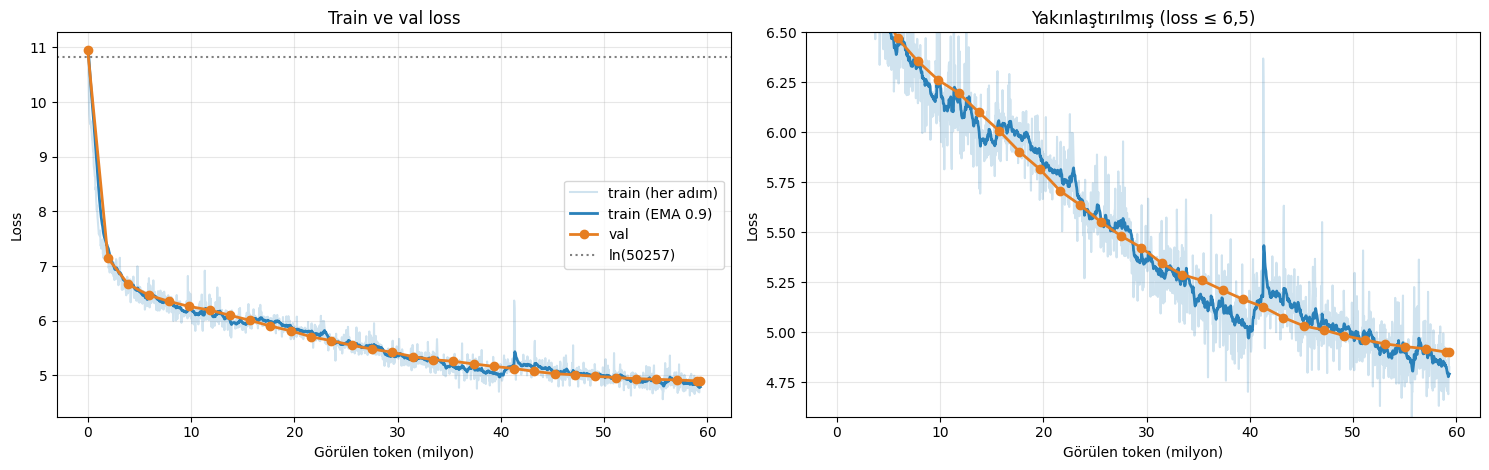

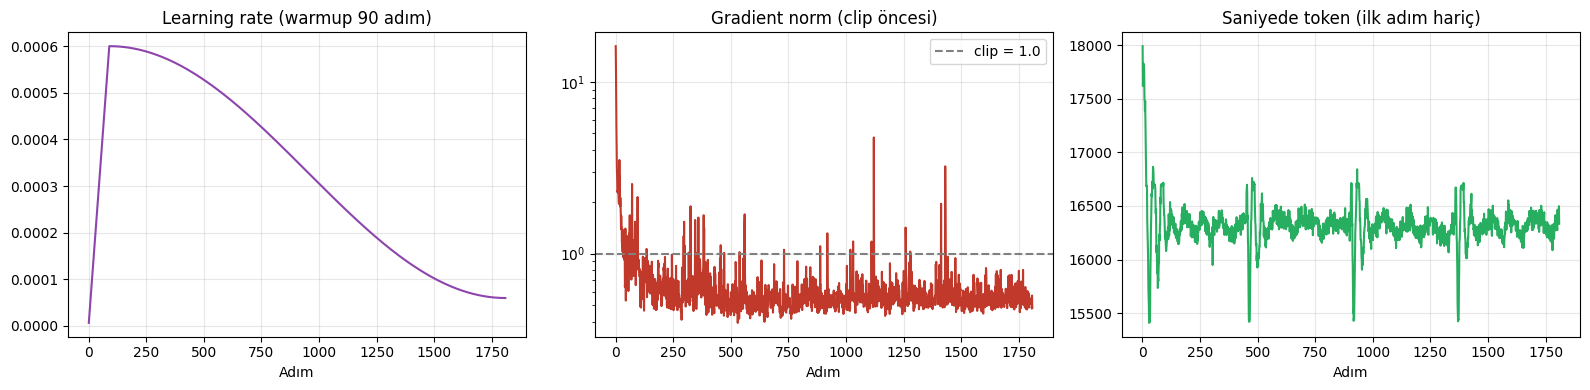

In [33]:
def summarize(res):
    L = res["log"]
    print(f"Adım sayısı        : {res['steps_done']:,} (planlanan {res['max_steps']:,}){'  <- erken durduruldu' if res['stopped_early'] else ''}")
    print(f"Gördüğü token      : {res['tokens_seen']:,} (≈ {res['tokens_seen']/1e6:.1f}M, train verisinin {res['tokens_seen']/res['n_train_tokens']:.2f} epoch'u)")
    print(f"Saniyede token     : {res['tok_s']:,.0f} (ilk 3 adım hariç ortalama)")
    print(f"Süre               : {res['train_seconds']/60:.1f} dk saf eğitim | {res['wall_seconds']/60:.1f} dk toplam (val/örnek/ckpt dahil)")
    print(f"Son train loss     : {res['final_train_loss']:.4f} (son 20 adımın ortalaması)")
    print(f"Son val loss       : {res['final_val_loss']:.4f} (perplexity ≈ {math.exp(res['final_val_loss']):.1f}) | val − train = {res['final_val_loss'] - res['final_train_loss']:+.4f}")
    print(f"Token/parametre    : {res['tokens_seen'] / 124_439_808:.2f} (Karpathy'nin 10B koşusu ≈ {10e9/124_439_808:.0f})")
    print(f"Grad norm          : ilk adım {L['norm'][0]:.2f} | clip uygulanan adım {sum(n > 1.0 for n in L['norm'])}/{len(L['norm'])}")

def ema(xs, a=0.9):
    out, m = [], None
    for v in xs:
        m = v if m is None else a * m + (1 - a) * v
        out.append(m)
    return out

def plot_loss(res, hline=None):
    L, V = res["log"], res["val_log"]
    tr_tok, va_tok = np.array(L["tokens"]) / 1e6, np.array(V["tokens"]) / 1e6
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
    for ax in axes:
        ax.plot(tr_tok, L["loss"], color="#2980b9", alpha=0.22, label="train (her adım)")
        ax.plot(tr_tok, ema(L["loss"]), color="#2980b9", lw=2, label="train (EMA 0.9)")
        ax.plot(va_tok, V["loss"], "o-", color="#e67e22", lw=2, label="val")
        if hline: ax.axhline(hline[0], ls="--", color="#c0392b", label=hline[1])
        ax.set_xlabel("Görülen token (milyon)"); ax.set_ylabel("Loss"); ax.grid(alpha=0.3)
    axes[0].axhline(math.log(50257), ls=":", color="gray", label="ln(50257)")
    axes[0].set_title("Train ve val loss"); axes[0].legend()
    axes[1].set_ylim(min(min(V["loss"]), min(ema(L["loss"]))) - 0.2, 6.5); axes[1].set_title("Yakınlaştırılmış (loss ≤ 6,5)")
    plt.tight_layout(); plt.show()

def plot_stats(res):
    L = res["log"]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].plot(L["step"], L["lr"], color="#8e44ad"); axes[0].set_title(f"Learning rate (warmup {res['warmup']} adım)")
    norms = np.array(L["norm"], dtype=float); norms[~np.isfinite(norms)] = np.nan
    axes[1].plot(L["step"], norms, color="#c0392b"); axes[1].axhline(1.0, color="gray", ls="--", label="clip = 1.0")
    axes[1].set_yscale("log"); axes[1].set_title("Gradient norm (clip öncesi)"); axes[1].legend()
    axes[2].plot(L["step"][1:], L["tok_s"][1:], color="#27ae60"); axes[2].set_title("Saniyede token (ilk adım hariç)")
    for a in axes: a.set_xlabel("Adım"); a.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

summarize(res_en)
plot_loss(res_en)
plot_stats(res_en)

## 3.4 Eğitim İlerledikçe Üretilen Metin Nasıl Değişiyor?
**Aynı prompt, aynı seed**, eğitimin farklı anlarında. Fark sadece modelden geliyor. Beklenen sıra: önce **kelimeler** (anlamlı token'lar), sonra **dilbilgisi** (cümle yapısı), en son **tutarlılık** (konuyu koruma).

In [34]:
def show_samples(res, n=3):
    for step in sorted(res["samples"]):
        vl = [v for s, v in zip(res["val_log"]["step"], res["val_log"]["loss"]) if s == step]
        print(f"\n=== adım {step:5d} | {step * total_batch_size / 1e6:6.1f}M token" + (f" | val loss {vl[0]:.3f}" if vl else ""))
        for i, t in enumerate(res["samples"][step][:n]):
            print(f"  [{i}] {t.replace(chr(10), ' ⏎ ')}")

show_samples(res_en)

print("\n\n######## Eğitim sonrası, daha uzun örnekler ########")
for p in ["Hello, I'm a language model,", "The capital of France is"]:
    print(f"\n>>> {p}")
    for i, t in enumerate(sample_text(res_en["raw_model"], p, n_seq=2, max_length=64, seed=7)):
        print(f"  [{i}] {t.replace(chr(10), ' ⏎ ')}")


=== adım     0 |    0.0M token | val loss 10.955
  [0] Hello, I'm a language model,ulaula flaw Creatinganticallycv TI2007 lied Continuous ● dissentagan368 608keesAS sponsorship minimalist toughest Awoken Mushroom Mushroomcollar
  [1] Hello, I'm a language model,iggs murderers criminal privilegedorigin legitimatelyListener improved Impossible bathroom Studentcollar ElephantBack loading privileged contributorsdx counterReilly appearingkan weeds unsolved
  [2] Hello, I'm a language model, glimpserint Posted Tight AX 306 lickycleListener relentless bathroom bathroom Beam tacticalCHR concedewasher reinventribution welf processesWritListenerCV

=== adım   226 |    7.4M token
  [0] Hello, I'm a language model, for the next state. As he says ⏎ And in the French were never made the most different in which it was in
  [1] Hello, I'm a language model, who cannot be a way to the story of a thing about these children (A, but is not all the past of
  [2] Hello, I'm a language model, the first point

### GÖREV 2 + 3 ANALİZİ VE DEĞERLENDİRME

**Eğitim sayıları:**
* Donanım: T4 (Colab), süre: 60,6 dk saf eğitim (62,0 dk val/örnek/ckpt dahil), 1.810 adım, adım başına 32.768 token.
* **Gördüğü token:** 59,3 M. **Saniyede token:** 16.318. **Son train loss:** 4,79. **Son val loss:** 4,90 (perplexity ≈ 134).
* Hafta 11'de eğitim döngüsünde ~17.000 tok/s ölçmüştük. Şimdi 16.318. Hız ölçümü 1830 ms/adım demişti, eğitimde ~2000 ms'e çıktı (yaklaşık %9). Muhtemel nedenler: T4'ün uzun süre yük altında hız düşürmesi, ölçümde optimizer adımının olmaması, araya giren val ölçümleri.

**Train ve val loss:** Loss 10,95'ten 4,79'a indi (val 10,96 → 4,90). Val − train farkı +0,105. Veriyi 1,19 epoch gördüğümüz için ilk shard'ların bir kısmı ikinci kez geldi, ama overfit belirgin değil (fark küçük, val loss hâlâ düşüyordu). Val loss'u neden her seferinde aynı batch'lerle (`reset`) ölçüyoruz? Çünkü farklı batch'lerle ölçsek loss'taki değişim modelden mi veri gürültüsünden mi geldiği anlaşılmazdı.

**Gradient norm ve LR:** İlk adımda norm 16,10. Warmup sırasında hızla ~1'e indi, LR zirveye çıkınca (adım 90) kısa bir süre 1,3'e sıçradı, sonra çoğunlukla 0,4–0,7 arasında kaldı. Clip 97 adımda devreye girdi (%5,4), çoğu ilk ~100 adımda. (Hafta 11'deki 150 adımlık koşuyla kıyasla.)

**Üretilen metin nasıl değişti?**
* Adım 0: rastgele token yığını ("ulaula flaw Creatinganticallycv...").
* İlk çeyrekte (adım 226–452): gerçek kelimeler var ama cümle yapısı yok, anlamsız ("for the next state. As he says...").
* Ortada (adım ~900–1130): cümleler dilbilgisi olarak daha düzgün, ama konuyu koruyamıyor.
* Sonda: akıcı İngilizce cümleler ("I am writing it; to remember what I wanted to do..."). Hâlâ yapamadığı: konu tutarlılığı ve olgusal doğruluk. "The capital of France is" ne üretti? "a capital bank (which also a nation)..." ve "known as the second and capital of India", yani yanlış. 59M token'la bilgi değil sadece dil yapısı öğrenilmiş.


---
# GÖREV 4 — HellaSwag'de Ölç (3:28:23 – 3:56:21)

## 4.1 HellaSwag Nedir?

### Teori
Loss "bu iyi mi?" sorusunu cevaplamaz. Başka bir modelle karşılaştırmak için ortak bir **test** gerekir. HellaSwag (Zellers ve ark., 2019): bir **bağlam** (bir olayın başı: ActivityNet altyazısı ya da WikiHow) ve **4 olası devam**. Doğru olan, olayın gerçekte nasıl devam ettiği. Yanlış devamlar **adversarial filtering** ile seçilmiş: makineye makul, insana saçma görünenler. **Rastgele tahmin: %25.**

### Mantık: bir dil modeli çoktan seçmeli soruyu nasıl çözer?
Modelin "soru-cevap" yeteneği yok, sadece sonraki token'ı tahmin ediyor. O yüzden soruyu "**hangi devam daha olası?**" diye soruyoruz:
1. 4 satır kur: `bağlam + devam_i`.
2. Her satırda her token'ın loss'unu hesapla.
3. **Sadece devam kısmındaki** token'lara bak (bağlamın loss'u 4 satırda aynı, ayırt etmez). Bunun için bir **maske** kullanıyoruz. Maskeyi 1 kaydırıyoruz, çünkü devamın ilk token'ını **bağlamın son token'ındaki** logits tahmin eder.
4. En düşük loss'lu devam = modelin cevabı.

**İki ölçü:**
* `acc`: devam token'ları loss'unun **toplamı** en düşük olan. Uzun devamlar daha çok token olduğu için toplamda cezalı, kısalara kayma var.
* `acc_norm`: **ortalama** loss (toplam / token sayısı) en düşük olan. Uzunluğa karşı normalize. Karpathy (ve OpenAI'ın raporlama biçimi) **acc_norm**'u kullanıyor.

> `enc.encode(" " + devam)`: baştaki boşluk önemli. GPT-2 tokenizer'ı kelime başındaki boşluğu token'a dahil ediyor (`" the"` ≠ `"the"`).

### Karpathy'nin referans değerleri (aynı yöntem, tam 10.042 örnek)
`hellaswag.py` başlığına göre OpenAI GPT-2 124M: `acc = 0,2859`, `acc_norm = 0,2955`. GPT-2 XL (1,5B): `acc_norm = 0,4893`. Yani **124M modelin tam kümedeki tavanı bile ~%30**: rastgeleyle arada ~5 puan var. (Biz ilk 1000 örnekte GPT-2'yi %33,5 ölçtük, ilk 1000 biraz kolay çıkmış ya da gürültü, tam küme değeriyle doğrudan kıyaslama.) Bu yüzden örnek sayısı ve belirsizlik (±) önemli.

In [35]:
HS_URL = "https://raw.githubusercontent.com/rowanz/hellaswag/master/data/hellaswag_val.jsonl"

def hs_load(n):
    path = f"{WORK}/hellaswag_val.jsonl"
    if not os.path.exists(path):
        try:
            urllib.request.urlretrieve(HS_URL, path)
        except Exception as e:
            print("GitHub'dan inmedi:", type(e).__name__, "-> HuggingFace datasets deneniyor")
            from datasets import load_dataset
            ds = load_dataset("Rowan/hellaswag", split="validation")
            with open(path, "w") as f:
                for r in ds:
                    f.write(json.dumps(dict(ctx=r["ctx"], endings=r["endings"], label=int(r["label"]))) + "\n")
    out = []
    with open(path) as f:
        for line in f:
            out.append(json.loads(line))
            if len(out) == n:
                break
    return out

def render_example(ex):
    # 4 satır token + 4 satır maske (maske 1 olan yer = devam kısmı)
    ctx_tokens = enc.encode(ex["ctx"])
    tok_rows, mask_rows = [], []
    for end in ex["endings"]:
        end_tokens = enc.encode(" " + end)
        tok_rows.append(ctx_tokens + end_tokens)
        mask_rows.append([0] * len(ctx_tokens) + [1] * len(end_tokens))
    max_len = max(len(r) for r in tok_rows)
    tokens = torch.zeros((4, max_len), dtype=torch.long)
    mask = torch.zeros((4, max_len), dtype=torch.long)
    for i, (tr_, mr_) in enumerate(zip(tok_rows, mask_rows)):
        tokens[i, :len(tr_)] = torch.tensor(tr_)
        mask[i, :len(mr_)] = torch.tensor(mr_)
    return tokens, mask, int(ex["label"])

@torch.no_grad()
def completion_losses(fwd, tokens, mask):
    tokens, mask = tokens.to(device), mask.to(device)
    with amp_ctx():
        logits = fwd(tokens)
    logits = logits.float()
    shift_logits = logits[..., :-1, :].contiguous()
    shift_tokens = tokens[..., 1:].contiguous()
    losses = F.cross_entropy(shift_logits.view(-1, shift_logits.size(-1)), shift_tokens.view(-1), reduction="none").view(tokens.size(0), -1)
    # maskeyi de 1 kaydırıyoruz, devamın ilk token'ını bağlamın son konumu tahmin ediyor
    shift_mask = mask[..., 1:].contiguous()
    sum_loss = (losses * shift_mask).sum(dim=1)
    n_end = shift_mask.sum(dim=1)
    return sum_loss, n_end, sum_loss / n_end

@torch.no_grad()
def hs_eval(fwd, examples, desc=""):
    t0 = time.perf_counter()
    ok, ok_norm = 0, 0
    for ex in examples:
        tokens, mask, label = render_example(ex)
        sum_loss, _, avg_loss = completion_losses(fwd, tokens, mask)
        ok += int(sum_loss.argmin()) == label            # toplam loss'a göre tahmin
        ok_norm += int(avg_loss.argmin()) == label       # ortalama loss'a göre tahmin (acc_norm)
    n = len(examples)
    out = dict(desc=desc, n=n, acc=ok / n, acc_norm=ok_norm / n, n_correct_norm=ok_norm)
    print(f"{desc:<30} n={n} | acc {out['acc']:.4f} | acc_norm {out['acc_norm']:.4f} | doğru (norm): {ok_norm}/{n} | {time.perf_counter() - t0:.0f} sn")
    return out

hs_examples = hs_load(HS_N)
print(f"{len(hs_examples)} HellaSwag örneği yüklendi (tam doğrulama kümesi 10.042).")

GitHub'dan inmedi: HTTPError -> HuggingFace datasets deneniyor


README.md:   0%|          | 0.00/7.02k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 24.4MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 6.11MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/39905 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10003 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10042 [00:00<?, ? examples/s]

1000 HellaSwag örneği yüklendi (tam doğrulama kümesi 10.042).


## 4.2 Tek Bir Örneği Elle İzle
Ölçüm kodunu sayıya güvenmeden önce **bir örneği baştan sona görmek** gerekir: hangi devam kaç token, toplam ve ortalama loss ne, hangisini seçiyor? (Karpathy da `hellaswag.py`'de ilk 10 örneği bu şekilde yazdırıyor.)

In [36]:
def hs_explain(fwd, ex):
    tokens, mask, label = render_example(ex)
    sum_loss, n_end, avg_loss = completion_losses(fwd, tokens, mask)
    print("Bağlam:", ex["ctx"])
    for i, end in enumerate(ex["endings"]):
        print(f"  {i}) [{int(n_end[i]):2d} token | toplam {sum_loss[i]:6.2f} | ortalama {avg_loss[i]:5.3f}] {end}" + ("   <- DOĞRU" if i == label else ""))
    pa, pn = int(sum_loss.argmin()), int(avg_loss.argmin())
    print(f"  toplam loss -> {pa} {'✓' if pa == label else '✗'} | ortalama loss -> {pn} {'✓' if pn == label else '✗'}\n")

res_en["raw_model"].eval()
for k in range(3):
    hs_explain(lambda t: res_en["raw_model"](t)[0], hs_examples[k])
res_en["raw_model"].train();

Bağlam: A man is sitting on a roof. he
  0) [11 token | toplam  57.09 | ortalama 5.190] is using wrap to wrap a pair of skis.
  1) [ 6 token | toplam  45.85 | ortalama 7.642] is ripping level tiles off.
  2) [ 8 token | toplam  48.04 | ortalama 6.005] is holding a rubik's cube.
  3) [ 9 token | toplam  40.21 | ortalama 4.468] starts pulling up roofing on a roof.   <- DOĞRU
  toplam loss -> 3 ✓ | ortalama loss -> 3 ✓

Bağlam: A lady walks to a barbell. She bends down and grabs the pole. the lady
  0) [ 7 token | toplam  37.75 | ortalama 5.393] swings and lands in her arms.
  1) [ 6 token | toplam  36.04 | ortalama 6.006] pulls the barbell forward.
  2) [ 9 token | toplam  44.14 | ortalama 4.904] pulls a rope attached to the barbell.
  3) [ 9 token | toplam  39.71 | ortalama 4.412] stands and lifts the weight over her head.   <- DOĞRU
  toplam loss -> 1 ✗ | ortalama loss -> 3 ✓

Bağlam: Two women in a child are shown in a canoe while a man pulls the canoe while standing in the water, wit

## 4.3 Önce Ölçümün Doğruluğunu Doğrula: Rastgele Model %25 Bulmalı
Ölçüm kodunda hata varsa (maske kaymış, etiket yanlış) sonuç **sessizce** yanlış çıkar. En ucuz kontrol: eğitilmemiş, rastgele başlatılmış modelin %25 civarı bulması. Bunu Görev 3'te **adım 0'da kaydettiğimiz** checkpoint ile yapıyoruz. Çok farklı bir sayı (ör. %40 ya da %10) çıkarsa sorun kodda.

Sonra aynı kodla **eğitim boyunca kaydettiğimiz checkpoint'leri** ölçüp HellaSwag'in eğitimle nasıl yükseldiğini çizeceğiz (Karpathy'nin videodaki ikinci grafiği).

In [37]:
def load_ours(path):
    ck = torch.load(path, map_location=device)
    m = GPT(GPTConfig(**ck["config"])).to(device)
    m.load_state_dict(ck["model"])
    m.eval()
    return m, ck["tokens"]

hs_results, ck_tokens = {}, {}
for step, path in res_en["ckpts"]:
    m, toks = load_ours(path)
    name = f"bizim, adım {step}" + (" (rastgele)" if step == 0 else "")
    hs_results[name] = hs_eval(lambda t, m=m: m(t)[0], hs_examples, name)
    ck_tokens[name] = toks
    del m
    if device == "cuda": torch.cuda.empty_cache()

bizim, adım 0 (rastgele)       n=1000 | acc 0.2520 | acc_norm 0.2360 | doğru (norm): 236/1000 | 12 sn
bizim, adım 452                n=1000 | acc 0.2800 | acc_norm 0.2580 | doğru (norm): 258/1000 | 12 sn
bizim, adım 905                n=1000 | acc 0.2830 | acc_norm 0.2600 | doğru (norm): 260/1000 | 11 sn
bizim, adım 1358               n=1000 | acc 0.2880 | acc_norm 0.2860 | doğru (norm): 286/1000 | 12 sn
bizim, adım 1810               n=1000 | acc 0.2960 | acc_norm 0.2750 | doğru (norm): 275/1000 | 12 sn


## 4.4 OpenAI'ın GPT-2'si (124M)
HuggingFace'ten OpenAI'ın yayınladığı **GPT-2 124M** ağırlıklarını indirip **aynı** `hs_eval` ile **aynı** örneklerde ölçüyoruz. `hs_eval` "logits döndüren herhangi bir fonksiyon" aldığı için bizim modelimiz de HF modeli de aynı kodla ölçülür, karşılaştırma adil. (Hafta 10'da kendi modelimize bu ağırlıkları yükleyip aynı logits'i aldığımızı doğrulamıştık.)

In [38]:
hf_gpt2 = GPT2LMHeadModel.from_pretrained("gpt2").to(device).eval()
hs_results["OpenAI GPT-2 (124M)"] = hs_eval(lambda t: hf_gpt2(t).logits, hs_examples, "OpenAI GPT-2 (124M)")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

OpenAI GPT-2 (124M)            n=1000 | acc 0.3350 | acc_norm 0.3350 | doğru (norm): 335/1000 | 19 sn


## 4.5 Sonuç Tablosu, Grafik ve Aynı Veride Loss Karşılaştırması

**Belirsizlik:** $n$ örnekte doğru oranı $p$ ise standart hata $\sqrt{p(1-p)/n}$. $n=1000$, $p=0{,}30$ için %95 aralığı **±%2,8**. Bizim model ile GPT-2 arasındaki fark bundan küçükse "farklı" diyemeyiz.

**Val loss çizgisi:** Karpathy eğitim grafiğine OpenAI GPT-2'nin **aynı val verisindeki** loss'unu yatay çizgi olarak ekliyor. Biz de GPT-2'ye val shard'ımızı okutup aynısını yapıyoruz. (Dikkat: GPT-2 FineWeb-Edu dağılımında eğitilmedi, karşılaştırma tam adil değil. Karpathy de bunu not ediyor.)

,model,n,acc,acc_norm,± (%95),doğru (norm)
0,"bizim, adım 0 (rastgele)",1000,0.252,0.236,0.0263,236/1000
1,"bizim, adım 452",1000,0.280,0.258,0.0271,258/1000
2,"bizim, adım 905",1000,0.283,0.260,0.0272,260/1000
3,"bizim, adım 1358",1000,0.288,0.286,0.0280,286/1000
4,"bizim, adım 1810",1000,0.296,0.275,0.0277,275/1000
5,OpenAI GPT-2 (124M),1000,0.335,0.335,0.0293,335/1000


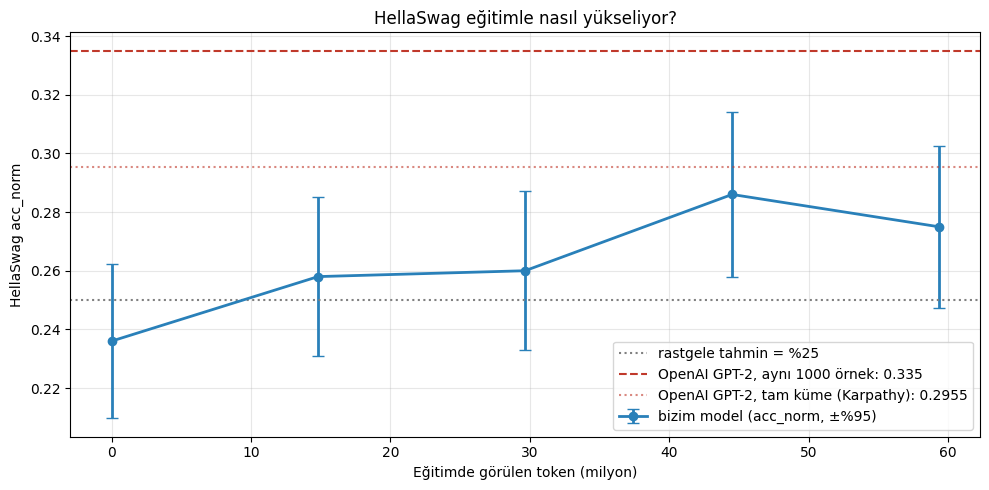


Aynı val verisi, 20 batch | bizim model: 4.8998 | OpenAI GPT-2: 3.2512 | fark: +1.649 nat


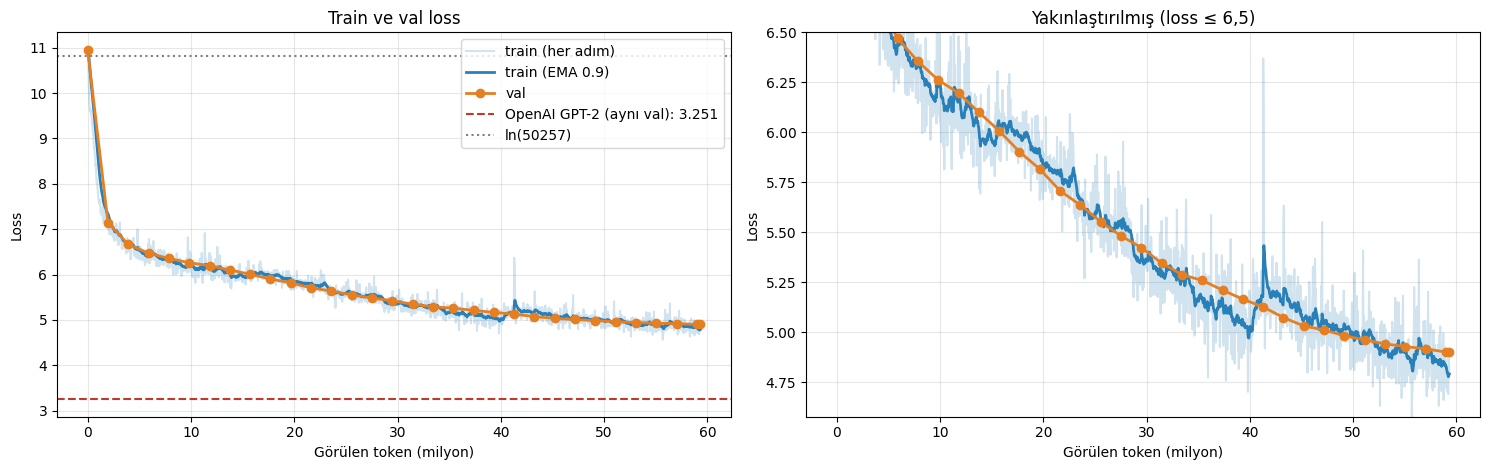

In [39]:
def ci95(p, n):
    return 1.96 * math.sqrt(p * (1 - p) / n)

df_hs = pd.DataFrame([{"model": k, "n": r["n"], "acc": round(r["acc"], 4), "acc_norm": round(r["acc_norm"], 4),
                       "± (%95)": round(ci95(r["acc_norm"], r["n"]), 4), "doğru (norm)": f"{r['n_correct_norm']}/{r['n']}"}
                      for k, r in hs_results.items()])
display(df_hs)

gpt2_r = hs_results["OpenAI GPT-2 (124M)"]
ours = [k for k in hs_results if k.startswith("bizim")]
xs = [ck_tokens[k] / 1e6 for k in ours]
ys = [hs_results[k]["acc_norm"] for k in ours]
fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(xs, ys, yerr=[ci95(y, HS_N) for y in ys], fmt="o-", color="#2980b9", capsize=4, lw=2, label="bizim model (acc_norm, ±%95)")
ax.axhline(0.25, color="gray", ls=":", label="rastgele tahmin = %25")
ax.axhline(gpt2_r["acc_norm"], color="#c0392b", ls="--", label=f"OpenAI GPT-2, aynı {HS_N} örnek: {gpt2_r['acc_norm']:.3f}")
ax.axhline(0.2955, color="#c0392b", ls=":", alpha=0.6, label="OpenAI GPT-2, tam küme (Karpathy): 0.2955")
ax.set_xlabel("Eğitimde görülen token (milyon)"); ax.set_ylabel("HellaSwag acc_norm")
ax.set_title("HellaSwag eğitimle nasıl yükseliyor?"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# aynı val verisinde bizim model mi iyi gpt-2 mi, loss'a bakalım
val_loader_eval = ShardLoader(DATA_DIR, "val", B, T, verbose=False)
ours_val = eval_val_loss(lambda t: res_en["raw_model"](t)[0], val_loader_eval, module=res_en["raw_model"])
gpt2_val = eval_val_loss(lambda t: hf_gpt2(t).logits, val_loader_eval)
print(f"\nAynı val verisi, {VAL_BATCHES} batch | bizim model: {ours_val:.4f} | OpenAI GPT-2: {gpt2_val:.4f} | fark: {ours_val - gpt2_val:+.3f} nat")
plot_loss(res_en, hline=(gpt2_val, f"OpenAI GPT-2 (aynı val): {gpt2_val:.3f}"))

### GÖREV 4 ANALİZİ VE DEĞERLENDİRME
> "Aradaki farkın nereden geldiği" kısmını **kendi cümlelerinle** yaz. Aşağıdakiler yönlendirme.

**Ölçüm koşulları:** HellaSwag doğrulama kümesinin ilk 1000 örneği (tamamı 10.042), HuggingFace `Rowan/hellaswag`'dan (GitHub indirmesi çalışmadı). İki model de aynı örnekler, aynı kod, aynı autocast ile ölçüldü.

| Model | acc | acc_norm | ± (%95) |
|---|---|---|---|
| Rastgele başlatılmış (adım 0) | 0,252 | 0,236 | 0,026 |
| Bizim model, %25 (adım 452) | 0,280 | 0,258 | 0,027 |
| Bizim model, %50 (adım 905) | 0,283 | 0,260 | 0,027 |
| Bizim model, %75 (adım 1358) | 0,288 | 0,286 | 0,028 |
| **Bizim model, son (adım 1810)** | 0,296 | 0,275 | 0,028 |
| **OpenAI GPT-2 (124M)** | 0,335 | 0,335 | 0,029 |
| Rastgele tahmin | 0,25 | 0,25 | – |

* **Sağlık kontrolü:** Rastgele model acc 0,252 / acc_norm 0,236 buldu (≈ 0,25 beklenir, ±0,026 aralığı %25'i kapsıyor). Bu, ölçüm kodunun çalıştığını gösteriyor.
* **Bizim model ne kadar buluyor?** acc_norm 0,275. Rastgeleden 2,5 puan yukarıda, OpenAI'ın GPT-2'sinden 6,0 puan geride. 2,5 puan ±2,8'in içinde, yani acc_norm'a göre rastgeleden anlamlı farklı diyemeyiz (acc'de fark daha net: 0,296). GPT-2 ile aradaki 6 puan belirsizlikten büyük, anlamlı.
* **Eğitimle yükseliş:** acc düzgün artıyor (0,252 → 0,280 → 0,283 → 0,288 → 0,296). acc_norm daha gürültülü (0,286 → 0,275 son adımda düşüş), bu düşüş ±2,8'in içinde, anlamlı değil.

**Aradaki farkın nereden geldiği (kendi cümlelerinle, yönlendirme):**
1. **Token sayısı:** Biz ≈ 59 M token gördük. GPT-2, WebText'te (~40 GB metin) çok daha fazlasını işledi. Karpathy'nin 10B'lik koşusu bizimkinin ~170 katı. Token/parametre oranımız 0,48, model doymaktan çok uzak.
2. **Veri farkı:** GPT-2 genel web (WebText), biz FineWeb-Edu (eğitici içerik). HellaSwag ise günlük aktiviteler ve WikiHow, ikisinden de farklı bir dağılım. (Kendi yorumun.)
3. **Loss ile HellaSwag ilişkisi:** Aynı val verisinde bizim loss 4,90, GPT-2'nin 3,25 (fark +1,65 nat). HellaSwag farkı ise sadece 6 puan. (HellaSwag ancak model devamları ayırt edecek kadar iyi olunca yükselir, küçük/az eğitilmiş modelde eğri düşük kalır.)
4. **Testin doğası:** Yanlış cevaplar adversarial filtering ile seçilmiş. 124M'lik GPT-2 tam kümede bile ~%30 (Karpathy: 0,2955).
5. **Ölçüm gürültüsü:** n=1000 ile ±2,8 puan. Bizimle GPT-2 arasındaki fark bu gürültüden büyük, bizimle rastgele arasındaki (acc_norm) küçük.

**`acc` vs `acc_norm`:** Bizim modelde acc 0,296, acc_norm 0,275. Karpathy'nin sayılarında acc_norm acc'den yüksek, bizde tersi. Fark sadece 2 puan, gürültü içinde, o yüzden "toplam loss uzun devamları cezalandırıyor" açıklamasını bu sonuca zorlamıyoruz. (GPT-2'de ikisi birebir 0,335 çıktı, tahminlerin kaç örnekte ayrıştığına ayrıca bakmaya değer.)


---
# Haftanın Özeti
> Çıktılarla dolduğunda hafta 11'in özet tablosunun devamı.

| Konu | Ne öğrendik |
|---|---|
| Veri hattı | FineWeb-Edu'yu bir kez tokenize edip `uint16` shard'lara (10M token/shard) yazdık, `<|endoftext|>` ile dokümanları ayırdık. Shard 0 = val. Loader shard bitince sonrakine geçiyor, val loader'ı her ölçümde `reset`. |
| İzleme | Val loss'u 60 adımda bir, 20 batch üzerinde ölçtük. Aynı prompt/seed ile örnek üretmek loss'un söylemediğini gösteriyor: önce rastgele token yığını, sonra gerçek kelimeler ve sonunda akıcı ama anlamsız cümleler. |
| Eğitim | 60,6 dk'da 59,3 M token (16.318 tok/s). Train loss 10,95 → 4,79, val loss 10,96 → 4,90. Token/parametre ≈ 0,48 (Karpathy ≈ 80). |
| HellaSwag | Rastgele 0,236, bizim model 0,275, OpenAI GPT-2 0,335 (acc_norm, n=1000, ±0,029). GPT-2 124M'in tam kümedeki değeri %29,6 (ilk 1000 örnekte biraz yüksek çıktı). |
| acc vs acc_norm | Toplam loss kısa devamları kayırıyor. Karpathy acc_norm raporluyor. |

**Seri tamamlandı:** *Neural Networks: Zero to Hero*'nun son halkasını bitirdik. Hafta 10'da mimari, hafta 11'de hızlı ve kararlı eğitim, bu hafta gerçek veri, izleme ve karşılaştırmalı ölçüm.